<a href="https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/02.Working_With_Text_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/02.Working_With_Text_Data.ipynb)

# Chapter 2 -- Working with Text Data

*Build a Large Language Model (From Scratch)* -- Sebastian Raschka (Manning, 2024)

**Technical edition -- setiap output di notebook ini dieksekusi riil di mesin builder; tidak ada output yang difabrikasi.**

Bab ini membangun jalur input LLM dari ujung ke ujung: teks mentah dipecah menjadi token, token dipetakan ke integer lewat vocabulary, deretan ID dipotong menjadi pasangan input-target dengan sliding window, lalu setiap ID diubah menjadi vektor lewat token embedding ditambah positional embedding. Produk akhirnya tensor `8 x 4 x 256` yang menjadi input modul attention di Chapter 3.

Kode bab adalah listing resmi companion repo [`rasbt/LLMs-from-scratch`](https://github.com/rasbt/LLMs-from-scratch) (Apache-2.0), verbatim dan berurutan seperti buku, dipin ke commit `cdbd33e`. Kode cetak buku berbeda dari repo di dua tempat yang mengubah perilaku, dan keduanya membuat kode cetak gagal (Errata #2 dan #4). Di satu tempat, token ID yang tercetak tidak bisa dihasilkan oleh kode yang tercetak (Errata #3). Errata #1 adalah catatan minor. Setiap versi cetak ikut dijalankan apa adanya, dan hasilnya dicatat beserta traceback atau pengukurannya. Arah sebaliknya juga ada: satu sel repo (`import importlib`) lebih rapuh daripada versi buku, meski hanya di luar Jupyter (catatan kalibrasi di 2.5). Sel tambahan yang bukan dari buku diberi komentar penanda di baris pertama.

Catatan kejujuran. Semua 78 sel kode **live**: dieksekusi builder di macOS-26.5.2-arm64-arm-64bit-Mach-O (Apple M1 Pro), Python 3.14.6, torch 2.14.1, tiktoken 0.14.0 (buku memakai tiktoken 0.7.0). Tidak ada sel replayed dan tidak ada sel unexecuted-by-design, karena seluruh bab selesai di CPU dalam hitungan detik. MPS tersedia di mesin ini, tetapi bab ini sengaja dijalankan di CPU (alasannya di sel setup). `the-verdict.txt` diunduh live dari GitHub saat build. Satu sel berakhir dengan error riil, yaitu demonstrasi `KeyError: 'Hello'` dari buku (sel repo, verbatim). Dua errata mencetak traceback riilnya lewat `traceback.print_exc()` supaya **Run all** tidak berhenti. Angka timing di UTH 3 spesifik mesin dan akan bergeser kalau dijalankan ulang; angka lain deterministik.

| Under the hood | What we measure | Result |
|---|---|---|
| **UTH 1** -- Lossy vs lossless | `decode(encode(x)) == x` di seluruh cerita, OOV pada 20% akhir cerita, biaya token satu pasang kalimat EN/ID | SimpleTokenizerV2 tidak identik (20479 -> 20684 karakter, 164 newline hilang, 526 blok beda); GPT-2 BPE identik. OOV 12.69% walau penulis dan ceritanya sama. Untuk satu pasang kalimat contoh, isi yang sama butuh 14 token (EN) vs 29 token (ID) |
| **UTH 2** -- BPE dari nol | 500 merge byte-level (pre-tokenisasi GPT-2 versi ASCII) yang dilatih hanya pada The Verdict, dibandingkan dengan tabel merge GPT-2 | Merge pertama `' t'` = merge pertama GPT-2 (rank 256); 4 merge pertama sama sebagai himpunan; 99/100 merge awal ada di vocab GPT-2. 500 merge: 7801 token vs 5145 milik GPT-2 |
| **UTH 3** -- Embedding = one-hot @ W | Nilai dan gradien lookup vs perkalian one-hot, plus biayanya | Selisih nilai 0.0, selisih gradien 0.0; lookup ~368x lebih cepat di batch 8x256; one-hot skala GPT-2 small = 1.65 GB |
| **UTH 4** -- Posisi dan attention | Self-attention mini satu head pada `" man bites dog."` vs `" dog bites man."`: tanpa mask, dengan causal mask, dengan positional embedding; plus token kembar di batch nyata | Tanpa mask dan tanpa posisi: output hanya permutasi (selisih 1.19e-07). Causal mask memecahnya sebagian (selisih 3.98), tetapi posisi terakhir tetap identik (1.19e-07). Dengan positional embedding: selisih 4.60. Token kembar: selisih token embedding 0.0000 |

## Setup

**Instalasi segar dan Run all.** Notebook ini butuh Python 3.10+ dan empat paket: `torch`, `tiktoken`, `requests`, `matplotlib`. Sel kode pertama di bawah memeriksa keempatnya dan memasang yang belum ada lewat `pip` ke interpreter kernel yang sedang jalan, jadi **Run all** di runtime segar (Colab, venv baru) tidak berhenti di import. Instalasi manual yang setara: `pip install torch tiktoken requests matplotlib`. Versi yang dipakai builder tercetak dua sel di bawah. Koneksi internet dibutuhkan untuk dua unduhan: `the-verdict.txt` (2.2) dan file BPE GPT-2 yang diambil tiktoken saat `get_encoding("gpt2")` dipanggil pertama kali.

**Satu sel sengaja berhenti dengan error**: demonstrasi `KeyError: 'Hello'` di 2.3, sel repo yang dipertahankan verbatim. Di Colab, Run all berhenti di sana; lanjutkan dengan *Runtime > Run after* dari sel sesudahnya (JupyterLab: *Run > Run Selected Cell and All Below*). Sel itu diberi tag `raises-exception`, sehingga `jupyter nbconvert --execute` dan nbclient melewatinya.

In [1]:
# Sel tambahan: cek dependensi untuk runtime segar (aman untuk Run all; hanya memasang yang belum ada)
import importlib.util, subprocess, sys

required = ["torch", "tiktoken", "requests", "matplotlib"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("python   :", sys.version.split()[0])
print("dicek    :", ", ".join(required))
print("dipasang :", ", ".join(missing) if missing else "tidak ada (semua sudah terpasang)")


python   : 3.13.16
dicek    : torch, tiktoken, requests, matplotlib
dipasang : tidak ada (semua sudah terpasang)


Di mesin builder keempat paket sudah terpasang, jadi tidak ada yang dipasang. Di runtime segar, paket yang baru dipasang bisa langsung di-import tanpa restart kernel, karena belum pernah di-import sebelumnya. Sel berikut dari repo mencetak versinya. Sel sesudahnya (tambahan builder) mencatat platform dan memilih device dengan urutan `cuda > mps > cpu`.

In [2]:
from importlib.metadata import version

print("torch version:", version("torch"))
print("tiktoken version:", version("tiktoken"))

torch version: 2.11.0+cpu
tiktoken version: 0.14.0


torch 2.14.1 dan tiktoken 0.14.0, jauh di atas versi di output tersimpan repo (torch 2.5.1, tiktoken 0.7.0). File merge dan vocab GPT-2 yang dipakai encoding `gpt2` bersifat tetap (tiktoken mengunduhnya dan mencocokkan hash-nya). Pola regex pre-tokenisasi dan peta token khusus, di sisi lain, tinggal di kode tiktoken sendiri. Karena itu kestabilan ID lintas versi bukan jaminan dari file saja, dan di 2.5 setiap ID dicocokkan langsung dengan buku.

In [3]:
# Sel tambahan (bukan dari buku): platform builder dan pemilihan device
import platform
import torch

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")
print("platform       :", platform.platform())
print("python         :", platform.python_version())
print("device tersedia:", device)
print("torch threads  :", torch.get_num_threads())
print("dipakai di bab :", "cpu")


platform       : Linux-6.6.122+-x86_64-with-glibc2.39
python         : 3.13.16
device tersedia: cpu
torch threads  : 1
dipakai di bab : cpu


Device terbaik yang terdeteksi adalah `mps` (Apple Silicon). Listing Chapter 2 tidak melatih model apa pun, dan operasi terberat di seluruh notebook (one-hot @ W di UTH 3, dengan tensor one-hot 411.7 MB) selesai dalam 37.70 ms di CPU. Semua tensor dibiarkan di CPU dengan dua alasan. Pertama, `torch.manual_seed(123)` di 2.7 menghasilkan bobot dari generator CPU, dan angka itulah yang tercetak di buku. Kedua, timing di UTH 3 lebih mudah dibandingkan bila tidak ada transfer device. Variabel `device` baru dipakai mulai Chapter 4-5, saat model GPT dilatih. Di CPU, PyTorch memakai 6 thread di mesin ini.

## 2.1 Understanding word embeddings

Semua yang terjadi di dalam jaringan saraf -- perkalian matriks, penjumlahan, gradien -- butuh bilangan riil. Token teks hanyalah simbol: "eagle" dikurangi "duck" tidak bermakna apa-apa. Setiap token harus diwakili vektor sebelum masuk model, dan menyiapkan perwakilan itu adalah pekerjaan bab ini.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.1.png" width="700">

**Figure 2.1** Peta buku: tiga stage, sembilan langkah. Chapter 2 adalah langkah 1 di stage 1 (data preparation & sampling); hasilnya menjadi input langkah 2, attention di Chapter 3.

Vektor perwakilan itu disebut *embedding*. Konsepnya tidak khusus untuk teks: gambar, audio, dan video juga punya encoder yang menghasilkan vektor. Encoder dilatih per jenis data, jadi vektor dari encoder audio tidak bermakna bagi model teks.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.2.png" width="700">

**Figure 2.2** Tiga modalitas, tiga encoder, satu bentuk output: vektor bilangan riil (di gambar hanya tiga angka per sampel).

Unit yang di-embed bisa sebesar dokumen, seperti yang umum di retrieval-augmented generation (RAG, di luar cakupan buku), atau sekecil token. GPT bekerja di level token karena ia menghasilkan teks token demi token.

Word2Vec adalah contoh klasik bahwa vektor bisa membawa makna. Ia dilatih dari pasangan kata dan tetangganya, sehingga kata yang sering berbagi konteks berakhir di wilayah ruang vektor yang sama.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.3.png" width="700">

**Figure 2.3** Bila vektornya hanya dua angka, embedding bisa digambar sebagai titik: burung berkumpul di satu pojok, negara dan ibu kota di pojok lain, dan long/longer/longest berderet berdekatan.

GPT tidak meminjam vektor Word2Vec. Matriks embedding-nya adalah parameter biasa: diacak di awal (2.7), lalu disetel oleh training bersama bobot lain (Chapter 5), sehingga vektornya mengikuti data dan tugas GPT sendiri. Lebarnya juga jauh di atas dua angka: 768 per token untuk GPT-2 terkecil (117M/125M parameter) dan 12288 untuk GPT-3 175B. Vektor yang lebih lebar memberi ruang representasi lebih besar, dengan biaya komputasi yang lebih mahal. Notebook ini memakai lebar 3 untuk contoh yang bisa dibaca mata dan 256 untuk versi realistis.

Jalurnya: teks -> token (2.2) -> token ID (2.3-2.5) -> pasangan input-target (2.6) -> vektor (2.7-2.8).

## 2.2 Tokenizing text

Token di bagian ini berupa kata atau satu karakter khusus, termasuk tanda baca.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.4.png" width="700">

**Figure 2.4** Posisi tokenisasi di jalur pemrosesan teks LLM: teks input dipecah menjadi token kata dan tanda baca, lalu menjadi token ID dan embedding. Angka token ID di gambar ini ilustratif; ID GPT-2 riil untuk kalimat yang sama diukur di 2.5.

Bahan latihannya cerpen "The Verdict" karya Edith Wharton. Teks ini sudah domain publik sehingga boleh dipakai untuk training LLM, dan repo buku menyediakan salinannya. Kode unduhan yang dicetak buku di 2.2 (tepat sebelum Listing 2.1, yang membaca file) memakai `urllib.request.urlretrieve`. Sejak [rasbt/LLMs-from-scratch#867](https://github.com/rasbt/LLMs-from-scratch/pull/867) (Oktober 2025), repo memakai `requests` karena `urllib` bermasalah bagi sebagian pembaca yang memakai VPN. Sel berikut adalah versi repo. Folder kerja builder dikosongkan di awal setiap build, sehingga cabang `if not os.path.exists(...)` benar-benar mengunduh.

In [4]:
import os
import requests

if not os.path.exists("the-verdict.txt"):
    url = (
        "https://raw.githubusercontent.com/rasbt/"
        "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
        "the-verdict.txt"
    )
    file_path = "the-verdict.txt"

    response = requests.get(url, timeout=30)
    response.raise_for_status()
    with open(file_path, "wb") as f:
        f.write(response.content)


# The book originally used the following code below
# However, urllib uses older protocol settings that
# can cause problems for some readers using a VPN.
# The `requests` version above is more robust
# in that regard.

"""
import os
import urllib.request

if not os.path.exists("the-verdict.txt"):
    url = ("https://raw.githubusercontent.com/rasbt/"
           "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
           "the-verdict.txt")
    file_path = "the-verdict.txt"
    urllib.request.urlretrieve(url, file_path)
"""

'\nimport os\nimport urllib.request\n\nif not os.path.exists("the-verdict.txt"):\n    url = ("https://raw.githubusercontent.com/rasbt/"\n           "LLMs-from-scratch/main/ch02/01_main-chapter-code/"\n           "the-verdict.txt")\n    file_path = "the-verdict.txt"\n    urllib.request.urlretrieve(url, file_path)\n'

Output di atas bukan hasil unduhan. Sel repo diakhiri string triple-quoted berisi kode `urllib` lama, dan Jupyter menampilkan string itu karena ia ekspresi terakhir sel; kode di dalamnya tidak dieksekusi. Unduhan via `requests` sendiri tidak mencetak apa pun.

Sel di bawah menjalankan kode unduhan versi cetak buku (`urllib`) untuk memeriksa apakah kode itu masih jalan dan menghasilkan byte yang sama. Satu deviasi disengaja: file tujuannya `the-verdict-urllib.txt`, bukan `the-verdict.txt`, supaya kegagalan jaringan tidak merusak file yang dibaca sel-sel berikutnya.

In [5]:
# Sel tambahan: kode unduhan versi cetak buku (urllib), dijalankan untuk kalibrasi ke file terpisah
import hashlib
import urllib.request

url = ("https://raw.githubusercontent.com/rasbt/"
       "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
       "the-verdict.txt")
file_path = "the-verdict-urllib.txt"     # knob: buku "the-verdict.txt"; dipisah agar file bab tidak tertimpa
sha_requests = hashlib.sha256(open("the-verdict.txt", "rb").read()).hexdigest()
try:
    urllib.request.urlretrieve(url, file_path)
    sha_urllib = hashlib.sha256(open(file_path, "rb").read()).hexdigest()
except Exception as e:                   # kalibrasi saja: kegagalan dicatat, bab tetap jalan
    sha_urllib = f"gagal: {type(e).__name__}: {e}"
print("sha256 via requests:", sha_requests)
print("sha256 via urllib  :", sha_urllib)
print("identik            :", sha_requests == sha_urllib)


sha256 via requests: b41e41a68f0398a3154ae69e2e4c0e2694e17fe0d66730536837f1b01935b31f
sha256 via urllib  : b41e41a68f0398a3154ae69e2e4c0e2694e17fe0d66730536837f1b01935b31f
identik            : True


Kedua jalur menghasilkan byte identik (SHA-256 `b41e41a68f0398a3...`). Kode unduhan versi cetak masih jalan bersih di mesin ini, dan pergantian ke `requests` di repo adalah soal ketahanan jaringan, bukan perubahan isi data. Hash ini juga menjadi sidik jari dataset: semua angka di bawah berlaku untuk file dengan hash tersebut.

In [6]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

print("Total number of character:", len(raw_text))
print(raw_text[:99])

Total number of character: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


20479 karakter, cocok digit-per-digit dengan buku. Ini Listing 2.1. Baris kedua menunjukkan masalah pertama yang harus ditangani tokenizer: `--` (double dash) menempel langsung ke kata di kedua sisinya (`genius--though`, `enough--so`).

In [7]:
# Sel tambahan: beberapa fakta tentang teks yang dipakai sepanjang bab
print("len(raw_text[:99]) :", len(raw_text[:99]))
print("karakter ke-100    :", repr(raw_text[99]))
print("ASCII murni        :", raw_text.isascii())
print("jumlah newline     :", raw_text.count("\n"))
print("kata (str.split)   :", len(raw_text.split()))
print("jumlah ':' dan ';' :", raw_text.count(":"), raw_text.count(";"))


len(raw_text[:99]) : 99
karakter ke-100    : 'g'
ASCII murni        : True
jumlah newline     : 164
kata (str.split)   : 3634
jumlah ':' dan ';' : 21 22


**Errata #1 (minor) -- `raw_text[:99]` mencetak 99 karakter, bukan 100.** Prosa buku menyebut 100 karakter pertama, padahal slice `[:99]` berhenti di indeks 98. Karakter ke-100 adalah `'g'` dari kata "great", sehingga output berakhir di `...so it was no `. Kode cukup diganti `raw_text[:100]` bila maksudnya memang 100. Dampaknya kosmetik.

Fakta lain yang akan dipakai nanti:
- Teks ini **ASCII murni**, jadi di UTH 2 setiap karakter tepat satu byte dan BPE level byte setara dengan BPE level karakter.
- Ada **164 newline**. Tokenizer sederhana di 2.3 membuang semuanya (diukur di UTH 1).
- `str.split()` menghasilkan **3634** potongan whitespace, baseline untuk menilai tokenizer regex di bawah.
- Ada **21 titik dua dan 22 titik koma**. Angka ini menjadi kunci Errata #2.

Tokenizer pertama dibangun hanya dengan `re.split`. Regex di sini alat sementara: mulai 2.5, tokenisasi diserahkan ke tokenizer GPT-2. Langkah pertama: split di whitespace, dengan grup penangkap `(\s)` supaya whitespace ikut dikembalikan sebagai elemen list.

In [8]:
import re

text = "Hello, world. This, is a test."
result = re.split(r'(\s)', text)

print(result)

['Hello,', ' ', 'world.', ' ', 'This,', ' ', 'is', ' ', 'a', ' ', 'test.']


Hasilnya 11 elemen: 6 potongan teks dan 5 spasi. Tanda baca masih menempel (`'Hello,'`, `'world.'`, `'This,'`). Teks sengaja tidak di-lowercase, karena huruf kapital membawa informasi (awal kalimat, nama seperti `Gisburn`). Harganya terlihat di UTH 1: `Are` dan `At` menjadi OOV walaupun `are` dan `at` sudah ada di vocabulary.

In [9]:
result = re.split(r'([,.]|\s)', text)

print(result)

['Hello', ',', '', ' ', 'world', '.', '', ' ', 'This', ',', '', ' ', 'is', ' ', 'a', ' ', 'test', '.', '']


Koma dan titik kini terpisah, tetapi list membengkak menjadi 19 elemen: 6 kata, 4 tanda baca, 5 spasi, dan 4 string kosong `''`. Tiga string kosong muncul di antara dua pemisah yang bersebelahan (koma atau titik yang langsung diikuti spasi), dan satu lagi di ujung list karena teks berakhir dengan pemisah `.`.

In [10]:
# Strip whitespace from each item and then filter out any empty strings.
result = [item for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'This', ',', 'is', 'a', 'test', '.']


Tinggal 10 token: 6 kata dan 4 tanda baca. List menyusut dari 19 menjadi 10 elemen, tetapi informasi spasi hilang permanen; UTH 1 mengukur bahwa ke-164 newline cerita lenyap setelah round trip. Tokenizer BPE di 2.5 menyimpan whitespace di dalam token, sehingga round trip-nya identik.

Pola regex diperluas untuk tanda tanya, titik dua, titik koma, garis bawah, tanda seru, kutip, kurung, dan `--`, lalu setiap potongan di-`strip()`.

In [11]:
text = "Hello, world. Is this-- a test?"

result = re.split(r'([,.:;?_!"()\']|--|\s)', text)
result = [item.strip() for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


10 token, persis seperti Figure 2.5. `this--` terpecah menjadi `this` dan `--` karena `--` adalah alternatif tersendiri di pola (`|--|`), dan `?` di akhir kini berdiri sendiri.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.5.png" width="700">

**Figure 2.5** Hasil sel di atas dalam bentuk gambar: `Hello, world. Is this-- a test?` menjadi 10 token.

Tokenizer yang sama diterapkan ke seluruh cerita.

In [12]:
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
print(preprocessed[:30])

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


Pemeriksaan visual 30 token pertama: `genius--though` menjadi tiga token (`genius`, `--`, `though`), begitu juga `enough--so`, dan koma di `that, in` berdiri sendiri. Tidak ada token yang masih membawa tanda baca.

In [13]:
print(len(preprocessed))

4690


4690 token, cocok digit-per-digit dengan buku. Dibanding 3634 potongan `str.split()`, ada tambahan 1056 token (4690 - 3634), seluruhnya berasal dari tanda baca dan `--` yang kini dipisahkan, karena di luar itu kedua metode memotong di whitespace yang sama.

## 2.3 Converting tokens into token IDs

Token string perlu dipetakan ke integer sebelum bisa diubah menjadi vektor. Pemetaan itu disebut vocabulary: daftar semua token unik di dataset, diurutkan, lalu masing-masing diberi integer unik yang disebut token ID.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.6.png" width="700">

**Figure 2.6** Versi mainan dari sel berikut: satu kalimat tanpa tanda baca menghasilkan vocabulary 8 entri, sedangkan The Verdict menghasilkan 1130.

In [14]:
all_words = sorted(set(preprocessed))
vocab_size = len(all_words)

print(vocab_size)

1130


1130 token unik dari 4690 token, cocok dengan buku. Rata-rata setiap token unik muncul 4690 / 1130 = 4.15 kali. Angka ini kecil karena dataset hanya satu cerpen; vocabulary sekecil ini akan bolong begitu bertemu teks lain (UTH 1 mengukurnya).

In [15]:
vocab = {token:integer for integer,token in enumerate(all_words)}

In [16]:
for i, item in enumerate(vocab.items()):
    print(item)
    if i >= 50:
        break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


Kelima entri yang dicetak buku (indeks 0-2, lalu `('Her', 49)` dan `('Hermia', 50)` setelah tanda elipsis) cocok, dan ke-51 entri identik dengan output tersimpan di repo. Entri 0-10 adalah tanda baca (`!` sampai `?`), dan kata pertama, `A`, baru muncul di indeks 11.

"Alfabetis" di sini berarti urutan code point dari `sorted()`, bukan urutan kamus. Semua huruf kapital (A-Z = 65-90) datang sebelum semua huruf kecil (a-z = 97-122), sehingga `HAD` (44) dan `Had` (45) mendahului `a`. Tanda baca dengan code point 33-63 (`!` sampai `?`) mendahului semuanya, kecuali `_` (code point 95), yang jatuh di antara kata berhuruf kapital dan kata berhuruf kecil. Untuk tokenizer ini tidak ada masalah, karena ID hanyalah label dan embedding akan dipelajari. Konsekuensinya praktis: ID spesifik di sel-sel berikut bergantung pada aturan sortir ini, dan vocabulary yang dibangun dengan sortir lain akan memberi ID berbeda untuk teks yang sama.

Langkah berikutnya: vocabulary ini dipakai untuk memetakan teks baru ke token ID.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.7.png" width="700">

**Figure 2.7** Vocabulary dibangun sekali dari training set, lalu dipakai ulang untuk teks apa pun. Teks baru yang memuat kata di luar 1130 entri itu memicu `KeyError: 'Hello'` beberapa sel di bawah.

Untuk mengubah output model kembali menjadi teks, dibutuhkan arah sebaliknya: inverse vocabulary yang memetakan ID ke token. Listing 2.3 membungkus kedua arah dalam satu kelas. `encode` memecah teks dan memetakan token ke ID; `decode` memetakan ID kembali ke token, menggabungkannya dengan spasi, lalu menghapus spasi sebelum tanda baca.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.8.png" width="700">

**Figure 2.8** Kelas tokenizer bekerja dua arah: `encode` lewat vocabulary dan `decode` lewat inverse vocabulary. Contoh di gambar memakai vocabulary mainan; versi The Verdict ada di sel-sel berikut.

Sel berikut adalah versi repo. Versi cetak buku berbeda satu detail di regex `encode`, dan perbedaan itu baru terlihat di Errata #2 setelah demo.

In [17]:
class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)

        preprocessed = [
            item.strip() for item in preprocessed if item.strip()
        ]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # Replace spaces before the specified punctuations
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

In [18]:
tokenizer = SimpleTokenizerV1(vocab)

text = """"It's the last he painted, you know,"
           Mrs. Gisburn said with pardonable pride."""
ids = tokenizer.encode(text)
print(ids)

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


21 ID, cocok digit-per-digit dengan buku. ID `1` (tanda kutip ganda) muncul di indeks 0 dan 12, `5` (koma) dua kali, dan `7` (titik) dua kali. String input sebenarnya terdiri dari dua baris: repo menulisnya dengan baris baru dan indentasi di tengah triple-quoted string, dan whitespace itu hilang begitu saja saat encode.

In [19]:
tokenizer.decode(ids)

'" It\' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.'

Hasil decode **tidak identik** dengan input. Input memuat `"It's`, sedangkan decode menghasilkan `" It' s`: ada spasi setelah kutip pembuka dan spasi di dalam kontraksi. Baris baru dan indentasi di tengah input juga lenyap. Penyebabnya, informasi spasi asli sudah dibuang saat encode. `decode` hanya bisa menggabung semua token dengan spasi lalu menghapus spasi *sebelum* tanda baca tertentu; spasi *sesudah* kutip pembuka dan sebelum `s` tidak tertangani.

Buku menyebut decode ini berhasil mengembalikan teks asli. Yang sebenarnya kembali adalah **deret token yang sama**, bukan string yang sama. UTH 1 mengukur besar selisihnya di seluruh cerita.

Catatan tampilan: repo menampilkan hasil sebagai nilai ekspresi terakhir sel, sehingga Jupyter mencetak `repr` (dengan kutip luar dan `\'`). Buku menampilkan `repr` yang sama walaupun kode cetaknya `print(tokenizer.decode(ids))`, yang tidak akan menampilkan kutip luar. Nilai string-nya sendiri cocok.

In [20]:
tokenizer.decode(tokenizer.encode(text))

'" It\' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.'

Hasilnya sama persis dengan sel sebelumnya, karena `tokenizer.encode(text)` menghasilkan 21 ID yang sama. Round trip ini tetap mendarat di string yang dinormalisasi, bukan di input asli.

Vocabulary hanya berisi token yang pernah muncul di The Verdict. Kata lain langsung bermasalah. Sel berikut berhenti dengan error, dan itu disengaja (lihat catatan Run all di Setup).

In [21]:
tokenizer = SimpleTokenizerV1(vocab)

text = "Hello, do you like tea. Is this-- a test?"

tokenizer.encode(text)

KeyError: 'Hello'

`KeyError: 'Hello'` riil, seperti yang diperkirakan buku. `Hello` tidak pernah muncul di The Verdict, sehingga `self.str_to_int['Hello']` gagal di token pertama. Teks contoh di repo sedikit berbeda dari buku (`"Hello, do you like tea. Is this-- a test?"`, buku: `"Hello, do you like tea?"`); error-nya sama karena kegagalan terjadi di token pertama. Pelajarannya: vocabulary harus dibangun dari training set yang besar dan beragam, atau tokenizer butuh jalan keluar untuk kata yang tidak dikenal (2.4 dan 2.5). Di Colab, lanjutkan dari sel berikut dengan *Runtime > Run after*.

### Errata #2 -- regex `encode` di Listing 2.3 versi cetak tidak memisahkan `:` dan `;`

Di halaman buku, `SimpleTokenizerV1.encode` memakai pola `r'([,.?_!"()\']|--|\s)'`, padahal vocabulary di atas dibangun dengan `r'([,.:;?_!"()\']|--|\s)'` (tanda `:` dan `;` ada). Repo sudah memakai pola lengkap. Demo buku tetap lolos karena kalimat contohnya tidak mengandung titik dua atau titik koma. Sel berikut menjalankan kelas versi cetak apa adanya terhadap teks yang dipakai untuk membangun vocabulary-nya sendiri. Versi repo disimpan dulu supaya bisa dipulihkan, dan traceback dicetak lewat `traceback.print_exc()` supaya Run all berlanjut.

In [22]:
# Errata #2 -- Listing 2.3 persis seperti tercetak di buku (regex encode tanpa ':' dan ';')
import traceback
if "SimpleTokenizerV1_repo" not in globals():   # simpan versi repo sekali saja (aman bila sel diulang)
    SimpleTokenizerV1_repo = SimpleTokenizerV1

class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}
    def encode(self, text):
        preprocessed = re.split(r'([,.?_!"()\']|--|\s)', text)
        preprocessed = [
            item.strip() for item in preprocessed if item.strip()
        ]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

try:
    SimpleTokenizerV1(vocab).encode(raw_text)   # teks training-nya sendiri
except KeyError:
    traceback.print_exc()                       # traceback riil, dicetak agar Run all berlanjut


Traceback (most recent call last):
  File "/tmp/ipykernel_2251/897634947.py", line 23, in <cell line: 0>
    SimpleTokenizerV1(vocab).encode(raw_text)   # teks training-nya sendiri
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/tmp/ipykernel_2251/897634947.py", line 15, in encode
    ids = [self.str_to_int[s] for s in preprocessed]
           ~~~~~~~~~~~~~~~^^^
KeyError: 'up;'


**Errata #2 -- `encode` versi cetak tidak memotong `:` dan `;`.** Traceback di atas riil: tokenizer versi cetak gagal pada teks yang dipakai untuk membangun vocabulary-nya sendiri. Token `'up;'` (dari `...my picture 'way up; but...`) tidak ada di vocab, karena vocab hanya mengenal `up` dan `;` sebagai dua token terpisah. Dengan pola cetak, `;` dan `:` tidak lagi menjadi titik potong, sehingga setiap kata yang ditempeli keduanya menjadi token baru yang tidak dikenal. Ini bug laten: tidak terlihat di demo buku, dan langsung muncul begitu teks mengandung titik koma. Kelas versi cetak sudah terdefinisi sebelum exception terjadi, jadi sel berikut memulihkan versi repo lalu menghitung skala masalahnya.

In [23]:
# Koreksi Errata #2: pulihkan versi repo (pola lengkap [,.:;?_!"()\']) lalu ukur
SimpleTokenizerV1 = SimpleTokenizerV1_repo

printed_tokens = [t.strip() for t in re.split(r'([,.?_!"()\']|--|\s)', raw_text) if t.strip()]
unknown_printed = [t for t in printed_tokens if t not in vocab]
print("pola cetak : token tak dikenal =", len(unknown_printed), "->", unknown_printed[:6], "...")

ids_full = SimpleTokenizerV1(vocab).encode(raw_text)
print("versi repo : encode(raw_text) =", len(ids_full), "ID")
print("sama dengan token saat vocab dibangun:", ids_full == [vocab[t] for t in preprocessed])
print("':'/';' di dalam token tak dikenal:", sum(t.count(":") + t.count(";") for t in unknown_printed),
      "dari", raw_text.count(":") + raw_text.count(";"),
      "| sisanya mengikuti kutip penutup:", [raw_text[m.start() - 13:m.start() + 1] for m in re.finditer(r'(?<=")[:;]', raw_text)])


pola cetak : token tak dikenal = 41 -> ['up;', 'eyes:', 'painting;', 'speculations;', 'palm-trees;', 'women:'] ...
versi repo : encode(raw_text) = 4690 ID
sama dengan token saat vocab dibangun: True
':'/';' di dalam token tak dikenal: 41 dari 43 | sisanya mengikuti kutip penutup: ['"interesting":', ' no "effects";']


Dengan pola cetak, **41 token** di cerita tidak dikenal (`up;`, `eyes:`, `painting;`, `speculations;`, `palm-trees;`, `women:`, ...), dan ke-41 token itu memuat tepat 41 tanda `:`/`;`, satu per token. Dari 43 tanda di seluruh teks (21 + 22), dua sisanya mengikuti kutip penutup (`"interesting":` dan `"effects";`). Kutip tetap menjadi titik potong di pola cetak, sehingga `:`/`;` itu tersisa sebagai token tunggal yang dikenal. Versi repo meng-encode seluruh cerita menjadi 4690 ID, dan deret ID-nya identik dengan token saat vocabulary dibangun. Encode dan pembangunan vocabulary memakai pola yang sama, dan memang harus begitu. Akar masalahnya: pola regex ditulis dua kali (sekali untuk vocabulary, sekali di dalam kelas), dan kedua salinan itu tidak lagi sama.

## 2.4 Adding special context tokens

Tokenizer butuh jalan keluar untuk kata yang tidak dikenal, dan model butuh penanda batas antardokumen. Keduanya diselesaikan dengan token khusus: `<|unk|>` menggantikan kata di luar vocabulary, dan `<|endoftext|>` memisahkan sumber teks yang tidak berhubungan.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.9.png" width="700">

**Figure 2.9** Dua entri baru di ujung vocabulary. ID di gambar ilustratif; di vocabulary The Verdict keduanya menjadi `<|endoftext|>` = 1130 dan `<|unk|>` = 1131 (dua sel di bawah).

Data training GPT adalah banyak dokumen yang disambung menjadi satu aliran panjang. Tanpa penanda, akhir satu dokumen dan awal dokumen berikutnya terlihat seperti kelanjutan. `<|endoftext|>` di setiap batas memutus kesan itu.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.10.png" width="700">

**Figure 2.10** Empat dokumen yang tidak saling berhubungan (laporan olahraga, dongeng, berita pasar saham, kisah pendek) disambung menjadi satu aliran training, dengan `<|endoftext|>` di setiap batas.

In [24]:
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])

vocab = {token:integer for integer,token in enumerate(all_tokens)}

In [25]:
len(vocab.items())

1132

1132 = 1130 + 2 token khusus, cocok dengan buku. (Prosa buku sempat menulis `<unk>` tanpa garis tegak; kodenya memakai `<|unk|>`.)

In [26]:
for i, item in enumerate(list(vocab.items())[-5:]):
    print(item)

('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


`<|endoftext|>` = 1130 dan `<|unk|>` = 1131, cocok dengan buku. Keduanya ditambahkan dengan `extend` **setelah** sortir, sehingga mendapat dua ID terakhir. Kalau ikut disortir, karakter `<` (code point 60) akan menempatkan keduanya di antara `;` (59) dan `?` (63) dan menggeser ID semua token sesudahnya.

Listing 2.4 menambahkan satu langkah ke `encode`: setiap token yang tidak ada di vocabulary diganti `<|unk|>`. Regex di `decode` juga diperluas dengan `:` dan `;`.

In [27]:
class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = { i:s for s,i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        preprocessed = [
            item if item in self.str_to_int
            else "<|unk|>" for item in preprocessed
        ]

        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # Replace spaces before the specified punctuations
        text = re.sub(r'\s+([,.:;?!"()\'])', r'\1', text)
        return text

In [28]:
tokenizer = SimpleTokenizerV2(vocab)

text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."

text = " <|endoftext|> ".join((text1, text2))

print(text)

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.


Dua kalimat independen disambung dengan `" <|endoftext|> "`, dengan spasi di kedua sisi pemisah.

In [29]:
tokenizer.encode(text)

[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]

16 ID, cocok digit-per-digit dengan buku. `1130` muncul sekali (pemisah dokumen), dan `1131` dua kali: untuk `Hello` di awal dan `palace` di akhir. Tokenizer tidak lagi crash; kata yang tidak dikenal kini dipetakan ke satu ID bersama.

In [30]:
tokenizer.decode(tokenizer.encode(text))

'<|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.'

`Hello` dan `palace` kembali sebagai `<|unk|>`, jadi keduanya memang tidak ada di The Verdict. Informasinya hilang permanen: semua kata yang tidak dikenal runtuh ke ID 1131 dan nanti ke satu vektor yang sama, sehingga model tidak bisa membedakan "palace" dari "Hello".

Dua token khusus ini bukan satu-satunya konvensi:
- Sebagian tokenizer lain memakai `[BOS]`, `[EOS]`, dan `[PAD]` (awal sekuens, akhir sekuens, pengisi batch). Tokenizer GPT-2 tidak punya ketiganya. `<|endoftext|>` (ID 50256 di GPT-2) merangkap pemisah dokumen dan, di Chapter 6-7, token padding. ID apa pun bisa dipakai untuk padding, karena posisi padding dikecualikan lewat mask saat training.
- Tokenizer GPT-2 juga tidak punya `<|unk|>`. Di 2.5, `someunknownPlace` di-encode menjadi tiga subword yang dikenal, bukan satu ID pengganti.

## 2.5 Byte pair encoding

Tokenizer GPT-2 (juga GPT-3 dan model awal di balik ChatGPT) memakai byte pair encoding (BPE). Daripada mengimplementasikannya sendiri, buku memakai [`tiktoken`](https://github.com/openai/tiktoken), library open source OpenAI dengan inti Rust; kode buku ditulis untuk tiktoken 0.7.0.

In [31]:
# pip install tiktoken

In [32]:
import importlib
import tiktoken

print("tiktoken version:", importlib.metadata.version("tiktoken"))

tiktoken version: 0.14.0


tiktoken 0.14.0 di mesin builder. Sel ini dari repo, dan versi cetaknya di buku berbeda: buku menulis `from importlib.metadata import version`, sedangkan repo memakai `import importlib` lalu `importlib.metadata.version(...)`. Sel berikut menguji kedua varian di interpreter Python biasa, ditambah varian repo setelah modul kernel Jupyter dimuat.

In [33]:
# Sel tambahan: varian sel versi di interpreter Python biasa (subprocess segar)
import os, subprocess, sys
env = {**os.environ, "PYTHON_COLORS": "0"}   # traceback tanpa warna ANSI, sama di terminal dan kernel
snippets = {
    "repo, skrip biasa      ": "import importlib; import tiktoken; print(importlib.metadata.version('tiktoken'))",
    "repo, setelah ipykernel": "import ipykernel.kernelapp, importlib, tiktoken; print(importlib.metadata.version('tiktoken'))",
    "buku, skrip biasa      ": "from importlib.metadata import version; print(version('tiktoken'))",
}
for label, snippet in snippets.items():
    r = subprocess.run([sys.executable, "-c", snippet], capture_output=True, text=True, env=env)
    print(f"{label} -> {(r.stdout or r.stderr).strip().splitlines()[-1]}")
print("importlib.metadata sudah dimuat di proses notebook ini:", "importlib.metadata" in sys.modules)


repo, skrip biasa       -> AttributeError: module 'importlib' has no attribute 'metadata'
repo, setelah ipykernel -> 0.14.0
buku, skrip biasa       -> 0.14.0
importlib.metadata sudah dimuat di proses notebook ini: True


**Catatan kalibrasi (repo, bukan buku).** Di skrip atau REPL Python biasa, varian repo gagal dengan `AttributeError: module 'importlib' has no attribute 'metadata'`, karena `import importlib` (juga `import tiktoken`) tidak memuat submodul `importlib.metadata`. Di Jupyter dan Colab sel repo tetap jalan, bahkan sebagai sel pertama di kernel baru: modul kernel (`ipykernel`) sudah memuat `importlib.metadata` saat start, seperti terlihat di baris kedua. Varian buku jalan di semua kondisi. Jadi sel repo bergantung pada efek samping lingkungan: aman di notebook, gagal begitu disalin ke skrip Python biasa.

In [34]:
tokenizer = tiktoken.get_encoding("gpt2")

In [35]:
text = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
     "of someunknownPlace."
)

integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})

print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 34680, 27271, 13]


20 ID, dan 19 di antaranya cocok dengan buku. Bedanya di indeks 15: live menghasilkan `1659`, buku mencetak `286`. Output tersimpan di repo juga `1659`, jadi selisih ini bukan efek versi tiktoken.

In [36]:
strings = tokenizer.decode(integers)

print(strings)

Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace.


Decode memperlihatkan sumbernya: `terracesof`, tanpa spasi. Python menyambung dua string literal yang bersebelahan di dalam kurung tanpa pemisah (implicit concatenation), dan literal pertama berakhir di `terraces` tanpa spasi penutup. BPE mengembalikan persis apa yang diberikan kepadanya, termasuk salah ketik. Buku mencetak `terraces of`. Sel berikut membuktikan teks mana yang menghasilkan output buku.

In [37]:
# Sel tambahan (Errata #3): tambahkan satu spasi yang hilang, bandingkan dengan output cetak buku
book_ids = [15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250,
            8812, 2114, 286, 617, 34680, 27271, 13]
text_spaced = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces "
     "of someunknownPlace."
)
ids_spaced = tokenizer.encode(text_spaced, allowed_special={"<|endoftext|>"})
print("kode cetak    == output buku:", integers == book_ids,
      "| indeks beda:", [i for i, (a, b) in enumerate(zip(integers, book_ids)) if a != b])
print("teks berspasi == output buku:", ids_spaced == book_ids)
print("token 13-16 kode cetak :", [tokenizer.decode([i]) for i in integers[13:17]])
print("token 13-16 berspasi   :", [tokenizer.decode([i]) for i in ids_spaced[13:17]])
words_text = [t.strip() for t in re.split(r'([,.:;?_!"()\']|--|\s)', text) if t.strip()]
print("token regex di luar vocab 2.4 (1132):", [t for t in words_text if t not in vocab])


kode cetak    == output buku: False | indeks beda: [15]
teks berspasi == output buku: True
token 13-16 kode cetak : [' terr', 'aces', 'of', ' some']
token 13-16 berspasi   : [' terr', 'aces', ' of', ' some']
token regex di luar vocab 2.4 (1132): ['Hello', 'terracesof', 'someunknownPlace']


**Errata #3 -- output tiktoken yang tercetak di buku tidak dihasilkan oleh kode yang tercetak.** Kode di buku dan di repo sama-sama tanpa spasi setelah `terraces`, sehingga hasilnya `' terr' + 'aces' + 'of'`, dengan `of` tanpa spasi pembuka (ID 1659). Dengan satu spasi tambahan, tokennya menjadi `' terr' + 'aces' + ' of'` (ID 286), dan seluruh 20 ID cocok dengan output buku digit-per-digit. Output buku berasal dari teks yang berbeda satu spasi dari kode cetaknya. Koreksinya cukup menambahkan spasi di akhir literal pertama (`"... terraces "`).

Pelajarannya lebih luas daripada salah ketik. Untuk kata biasa, BPE tidak punya kondisi "tidak dikenal": setiap kata, termasuk typo, pecah menjadi subword yang ada di vocabulary. (Satu-satunya input yang ditolak tiktoken di bab ini adalah string token khusus seperti `<|endoftext|>` tanpa `allowed_special`, lihat Errata #4.) Akibatnya typo seperti `terracesof` lolos tanpa error dan baru terlihat bila ID dibandingkan dengan referensi. Tokenizer berbasis vocabulary kata justru akan menangkapnya. Baris terakhir output menunjukkan `terracesof` termasuk tiga token di luar vocabulary 1132, bersama `Hello` dan `someunknownPlace`. SimpleTokenizerV1 akan berhenti dengan `KeyError` (pada teks ini sudah lebih dulu di `'Hello'`), sedangkan SimpleTokenizerV2 akan menyembunyikannya sebagai `<|unk|>`.

Dua observasi buku tentang hasil BPE di atas. Pertama, `<|endoftext|>` mendapat ID besar, 50256. Kedua, `someunknownPlace` di-encode dan di-decode tanpa `<|unk|>`. Sel berikut memeriksa keduanya, sekaligus ID riil untuk kalimat contoh di Figure 2.4.

In [38]:
# Sel tambahan: ukuran vocab GPT-2, posisi <|endoftext|>, dan ID riil kalimat Figure 2.4
print("n_vocab                :", tokenizer.n_vocab)
print("eot_token              :", tokenizer.eot_token, repr(tokenizer.decode([tokenizer.eot_token])))
print("rank token biasa       :", min(tokenizer._mergeable_ranks.values()), "..",
      max(tokenizer._mergeable_ranks.values()))
fig_ids = tokenizer.encode("This is an example.")
print("'This is an example.'  :", fig_ids, [tokenizer.decode([i]) for i in fig_ids])
print("' someunknownPlace'    :", tokenizer.encode(" someunknownPlace"),
      [tokenizer.decode([i]) for i in tokenizer.encode(" someunknownPlace")])


n_vocab                : 50257
eot_token              : 50256 '<|endoftext|>'
rank token biasa       : 0 .. 50255
'This is an example.'  : [1212, 318, 281, 1672, 13] ['This', ' is', ' an', ' example', '.']
' someunknownPlace'    : [617, 34680, 27271] [' some', 'unknown', 'Place']


- **Vocabulary 50257** token: rank 0-50255 untuk token biasa (256 byte tunggal + 50000 merge), ditambah satu token khusus. `<|endoftext|>` memegang ID terbesar, 50256.
- **ID di Figure 2.4 ilustratif.** Gambar memakai `40134 2052 133 389 12`, padahal GPT-2 memberi `[1212, 318, 281, 1672, 13]` untuk `"This is an example."`. Kalimat contoh dan angka ID ilustratif yang sama dipakai ulang di Figure 2.15 dan 2.19.
- **Spasi menempel di depan token**: `' is'`, `' an'`, `' example'`. GPT-2 tidak membuang whitespace seperti tokenizer regex; spasi menjadi bagian dari token berikutnya, dan inilah yang membuat decode-nya lossless.
- **Kata tak dikenal pecah menjadi subword**: `someunknownPlace` menjadi `' some' + 'unknown' + 'Place'` (617, 34680, 27271), tiga potongan yang masing-masing ada di vocabulary. Tidak ada `<|unk|>`.

### Under the hood 1 -- Seberapa lossy tokenizer sederhana?

Buku membuat tiga klaim: decode SimpleTokenizer mengembalikan teks asli (2.3), vocabulary kecil tidak tahan terhadap teks baru (2.3-2.4), dan BPE bisa meng-encode kata apa pun tanpa `<|unk|>` (2.5). Ketiganya bisa diukur tanpa training:
- **(a)** round trip `decode(encode(x)) == x` di seluruh 20479 karakter cerita;
- **(b)** OOV pada data held-out: vocabulary dibangun dari 80% token awal cerita lalu diuji pada 20% sisanya. Penulis, gaya, dan ceritanya sama, jadi ini kondisi paling ramah yang mungkin;
- **(c)** teks di luar distribusi: satu kalimat Inggris dan terjemahan Indonesianya, ditulis builder untuk tes ini. Ini satu pasang contoh, bukan sampel korpus.

In [39]:
# Under the hood 1 -- lossy vs lossless (kode orisinal, bukan dari buku)
import collections, difflib

simple = SimpleTokenizerV2(vocab)          # vocab 1132 token dari 2.4
bpe = tiktoken.get_encoding("gpt2")

# (a) round trip di seluruh cerita
rt_simple = simple.decode(simple.encode(raw_text))
rt_bpe = bpe.decode(bpe.encode(raw_text))
diffs = [op for op in difflib.SequenceMatcher(None, raw_text, rt_simple, autojunk=False).get_opcodes()
         if op[0] != "equal"]
kinds = collections.Counter((raw_text[i1:i2], rt_simple[j1:j2]) for _, i1, i2, j1, j2 in diffs)
print("(a) round trip seluruh cerita")
print(f"    SimpleTokenizerV2 identik: {rt_simple == raw_text} | karakter {len(raw_text)} -> {len(rt_simple)}"
      f" | newline {raw_text.count(chr(10))} -> {rt_simple.count(chr(10))} | blok beda {len(diffs)}")
print("    jenis beda terbanyak (asli -> decode, jumlah):")
for (a, b), n in kinds.most_common(5):
    print(f"        {a!r:>8} -> {b!r:<6} {n}")
print(f"    '--' di teks asli: {raw_text.count('--')} | ' -- ' (berspasi) di hasil decode: {rt_simple.count(' -- ')}")
print(f"    GPT-2 BPE identik        : {rt_bpe == raw_text}")

# (b) OOV: vocabulary dari 80% token awal, diuji pada 20% sisanya
cut = int(0.8 * len(preprocessed))
seen, held_out = set(preprocessed[:cut]), preprocessed[cut:]
oov = [t for t in held_out if t not in seen]
print(f"(b) vocab dari {cut} token awal ({len(seen)} tipe), diuji pada {len(held_out)} token akhir")
print(f"    OOV {len(oov)} token = {len(oov) / len(held_out):.2%} ({len(set(oov))} tipe unik),"
      f" contoh {sorted(set(oov))[:6]}")
print("    bentuk huruf kecil 'are' / 'at' ada di vocab 80%:", "are" in seen, "/", "at" in seen)

# (c) satu pasang kalimat contoh: Inggris vs terjemahan Indonesianya
sentences = {"EN": "The model learns to predict the next word from the words before it.",
             "ID": "Model belajar memprediksi kata berikutnya dari kata-kata sebelumnya."}
ntok, tpw = {}, {}
for lang, s in sentences.items():
    ids_simple, ids_bpe = simple.encode(s), bpe.encode(s)
    ntok[lang], tpw[lang] = len(ids_bpe), len(ids_bpe) / len(s.split())
    print(f"(c) {lang}: {len(s.split())} kata | Simple {len(ids_simple)} token,"
          f" <|unk|> {ids_simple.count(vocab['<|unk|>'])} | BPE {len(ids_bpe)} token"
          f" = {tpw[lang]:.2f} token/kata, round trip {bpe.decode(ids_bpe) == s}")
print(f"    isi yang sama, token BPE ID/EN: {ntok['ID']}/{ntok['EN']} = {ntok['ID'] / ntok['EN']:.2f}x")
print("    potongan BPE kalimat ID:", [bpe.decode([i]) for i in bpe.encode(sentences["ID"])])


(a) round trip seluruh cerita
    SimpleTokenizerV2 identik: False | karakter 20479 -> 20684 | newline 164 -> 0 | blok beda 526
    jenis beda terbanyak (asli -> decode, jumlah):
              '' -> ' '    347
          '\n\n' -> ' '    41
          '\n\n' -> ''     39
              '' -> '"'    30
             '"' -> ''     30
    '--' di teks asli: 97 | ' -- ' (berspasi) di hasil decode: 94
    GPT-2 BPE identik        : True
(b) vocab dari 3752 token awal (1020 tipe), diuji pada 938 token akhir
    OOV 119 token = 12.69% (110 tipe unik), contoh ['Are', 'At', 'Begin', 'Devonshire', 'Greek', 'Hang']
    bentuk huruf kecil 'are' / 'at' ada di vocab 80%: True / True
(c) EN: 13 kata | Simple 14 token, <|unk|> 4 | BPE 14 token = 1.08 token/kata, round trip True
(c) ID: 8 kata | Simple 9 token, <|unk|> 8 | BPE 29 token = 3.62 token/kata, round trip True
    isi yang sama, token BPE ID/EN: 29/14 = 2.07x
    potongan BPE kalimat ID: ['Model', ' bel', 'aj', 'ar', ' mem', 'pred', 'i', 'ks', 'i

**(a) SimpleTokenizerV2 lossy, GPT-2 BPE lossless.** Hasil decode SimpleTokenizerV2 berbeda dari teks asli di 526 blok, dan panjangnya berubah dari 20479 menjadi 20684 karakter. Rinciannya:
- Ke-164 newline lenyap. Struktur paragraf hilang total; sebagian `\n\n` menjadi spasi dan sebagian hilang tanpa sisa.
- Spasi yang disisipkan (`'' -> ' '`) adalah jenis beda terbanyak. Sumber terbesarnya `--`: decode menyambung token dengan spasi dan tidak pernah menghapus spasi di sekitar `--`, sehingga dari 97 kemunculan `--` di teks asli, 94 kembali sebagai ` -- ` berspasi (`genius--though` menjadi `genius -- though`). Sisanya muncul di dalam kontraksi (`It' s`) dan setelah kutip pembuka.
- Pasangan `'"' -> ''` dan `'' -> '"'` adalah cara difflib mencatat kutip yang "bergeser" terhadap spasi di sekitarnya.

GPT-2 BPE mengembalikan 20479 karakter yang identik. Klaim buku di 2.3 ("decode berhasil mengembalikan teks asli") hanya berlaku bila "teks" berarti deret kata; di level string, klaim itu salah, dan selisihnya terukur.

**(b) OOV 12.69% bahkan di kondisi paling ramah.** Vocabulary dari 3752 token pertama berisi 1020 tipe, dan 119 dari 938 token terakhir tidak ada di dalamnya (110 tipe unik). `Are` dan `At` termasuk OOV, padahal bentuk huruf kecilnya (`are`, `at`) sudah ada di vocabulary 80%; bentuk kapitalnya saja yang belum pernah muncul. Keputusan tidak melakukan lowercase (2.2) memperbesar masalah OOV. BPE tidak punya OOV untuk kata biasa, karena kata apa pun bisa dirakit dari subword.

**(c) Satu pasang kalimat: round trip sempurna, biaya token timpang.** Untuk kalimat Inggris 13 kata, SimpleTokenizerV2 sudah menghasilkan 4 `<|unk|>`. Untuk kalimat Indonesia, 8 dari 8 kata menjadi `<|unk|>`, dan hanya titik yang selamat. BPE meng-encode keduanya tanpa `<|unk|>` dan dengan round trip sempurna. Isi yang sama butuh 14 token dalam bahasa Inggris dan 29 token dalam bahasa Indonesia (2.07x). Per kata, angkanya 1.08 vs 3.62 token, karena kalimat Indonesia memakai lebih sedikit kata yang lebih panjang. `belajar` terpotong menjadi `' bel' + 'aj' + 'ar'` dan `memprediksi` menjadi lima potongan.

Batas pengukuran ini: satu kalimat dan terjemahannya tidak cukup untuk menyimpulkan rasio umum antarbahasa atau biaya bahasa Indonesia. Estimasi yang sahih butuh korpus paralel. Yang ditunjukkan pasangan ini lebih sempit: vocabulary tetap yang diperoleh dari satu distribusi teks (merge GPT-2 dipelajari dari WebText) bisa memotong teks dari distribusi lain menjadi potongan yang jauh lebih kecil, dan efek itu bisa diukur dengan cara di atas untuk data apa pun.

### Exercise 2.1 -- BPE untuk kata yang tidak dikenal

Latihan: encode string `"Akwirw ier"` dengan tokenizer BPE, decode setiap ID satu per satu untuk mereproduksi Figure 2.11, lalu decode seluruh deret ID untuk memeriksa apakah input asli kembali utuh.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.11.png" width="700">

**Figure 2.11** Pecahan `"Akwirw ier"` versi buku: enam potongan, masing-masing satu ID GPT-2. Sel-sel di bawah mereproduksinya.

Solusi diambil verbatim dari `exercise-solutions.ipynb` di repo. Enam sel satu baris di sana (sel 8-13), yang meng-encode setiap potongan secara terpisah, dipadatkan menjadi satu sel.

In [40]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

In [41]:
integers = tokenizer.encode("Akwirw ier")
print(integers)

[33901, 86, 343, 86, 220, 959]


Enam ID `[33901, 86, 343, 86, 220, 959]`, cocok digit-per-digit dengan Figure 2.11.

In [42]:
for i in integers:
    print(f"{i} -> {tokenizer.decode([i])}")

33901 -> Ak
86 -> w
343 -> ir
86 -> w
220 ->  
959 -> ier


Pemetaannya `Ak`, `w`, `ir`, `w`, spasi, `ier`, persis seperti Figure 2.11. `w` muncul dua kali dengan ID yang sama (86), dan spasi berdiri sendiri sebagai token 220 alih-alih menempel ke `ier`. Sel berikut menjelaskan alasannya.

In [43]:
# Dipadatkan dari exercise-solutions.ipynb sel 8-13 (enam panggilan tokenizer.encode, satu per sel)
for piece in ["Ak", "w", "ir", "w", " ", "ier"]:
    print(f"{piece!r:>6} -> {tokenizer.encode(piece)}")

# Tambahan builder: rank merge yang relevan (rank lebih kecil = digabung lebih dulu)
gpt2_rank = tokenizer._mergeable_ranks
print({s: gpt2_rank.get(s.encode()) for s in ["er", "ie", "ier", " i", " ier"]})


  'Ak' -> [33901]
   'w' -> [86]
  'ir' -> [343]
   'w' -> [86]
   ' ' -> [220]
 'ier' -> [959]
{'er': 263, 'ie': 494, 'ier': 959, ' i': 1312, ' ier': None}


Setiap potongan, bila di-encode sendirian, kembali ke ID tunggal yang sama, sehingga pemetaan ini konsisten di kedua arah. Baris terakhir menjelaskan nasib `" ier"`. Pre-tokenizer GPT-2 menempelkan spasi ke kata berikutnya, lalu BPE berulang kali menggabungkan pasangan ber-rank terkecil di dalam potongan `" ier"`:
1. `e + r`: rank 263, paling kecil, jadi digabung pertama: `[' ', 'i', 'er']`.
2. `i + er` (rank 959) bersaing dengan `' ' + i` (rank 1312). Rank 959 lebih kecil, sehingga hasilnya `[' ', 'ier']`.
3. `' ier'` tidak ada di tabel (`None`), jadi proses berhenti dan spasi tersisa sebagai token 220.

In [44]:
tokenizer.decode([33901, 86, 343, 86, 220, 959])

'Akwirw ier'

`'Akwirw ier'` kembali utuh, termasuk spasinya. Latihan terjawab: kata yang tidak pernah ada di data training dipecah menjadi enam potongan yang semuanya ada di vocabulary, dan decode merekonstruksi input secara eksak.

### Under the hood 2 -- BPE dari nol di The Verdict

Buku tidak mengimplementasikan BPE. Ringkasannya: mulai dari karakter tunggal, lalu berulang kali gabungkan pasangan yang paling sering bersebelahan menjadi token baru, misalnya `d` + `e` menjadi `de`. Klaim ini cukup murah untuk dieksekusi.

Sel di bawah melatih BPE level byte dalam sekitar 40 baris, hanya pada The Verdict, sebanyak 500 merge. Pre-tokenisasinya adalah pola regex GPT-2 versi ASCII: cabang kontraksi (`'s`, `'t`, `'re`, ...), lalu kata dengan spasi menempel di depan, angka, tanda baca, dan whitespace. Untuk teks ASCII murni seperti The Verdict, potongannya sama dengan pola GPT-2 asli. Hasilnya dibandingkan dengan tabel merge GPT-2 asli lewat `tokenizer._mergeable_ranks`, atribut privat tiktoken: rank 0-255 untuk byte tunggal, rank 256 untuk merge pertama GPT-2, dan seterusnya. GPT-2 dilatih pada WebText (sekitar 40 GB teks web), sedangkan The Verdict hanya 20 kB.

In [45]:
# Under the hood 2 -- BPE byte-level mini, dilatih hanya pada The Verdict (kode orisinal)
import collections

# pola pre-tokenisasi GPT-2, dengan \p{L} -> [A-Za-z] dan \p{N} -> [0-9] (setara untuk teks ASCII)
PRETOK = re.compile(r"'s|'t|'re|'ve|'m|'ll|'d| ?[A-Za-z]+| ?[0-9]+| ?[^\sA-Za-z0-9]+|\s+(?!\S)|\s+")

def train_bpe(text, n_merges):
    words = collections.Counter(PRETOK.findall(text))
    corpus = {tuple(bytes([b]) for b in w.encode("utf-8")): c for w, c in words.items()}
    merges, curve = [], [sum(len(w) * c for w, c in corpus.items())]
    for _ in range(n_merges):
        pairs = collections.Counter()
        for w, c in corpus.items():
            for pair in zip(w, w[1:]):
                pairs[pair] += c
        (a, b), freq = max(pairs.items(), key=lambda kv: (kv[1], kv[0]))  # tie-break deterministik
        merges.append((a + b, freq, (a, b)))
        new_corpus = {}
        for w, c in corpus.items():
            out, i = [], 0
            while i < len(w):
                if i + 1 < len(w) and w[i] == a and w[i + 1] == b:
                    out.append(a + b)
                    i += 2
                else:
                    out.append(w[i])
                    i += 1
            new_corpus[tuple(out)] = new_corpus.get(tuple(out), 0) + c
        corpus = new_corpus
        curve.append(sum(len(w) * c for w, c in corpus.items()))
    return merges, curve

def encode_bpe(text, merges):
    rank = {m: r for r, (m, *_) in enumerate(merges)}
    pieces = []
    for w in PRETOK.findall(text):
        parts = [bytes([b]) for b in w.encode("utf-8")]
        while len(parts) > 1:
            r, j = min((rank.get(parts[k] + parts[k + 1], float("inf")), k) for k in range(len(parts) - 1))
            if r == float("inf"):
                break
            parts[j:j + 2] = [parts[j] + parts[j + 1]]
        pieces += parts
    return pieces

assert "".join(PRETOK.findall(raw_text)) == raw_text      # pre-tokenisasi tidak membuang apa pun
merges, curve = train_bpe(raw_text, 500)
gpt2_rank = tokenizer._mergeable_ranks

print("merge  token baru      frek  rank GPT-2")
for k, (m, freq, _) in enumerate(merges[:12], 1):
    print(f"{k:>5}  {m!r:<14} {freq:>5}  {gpt2_rank.get(m)}")
in_gpt2 = [gpt2_rank.get(m) for m, *_ in merges[:100]]
print(f"\n100 merge pertama: {sum(r is not None for r in in_gpt2)} ada di vocab GPT-2,"
      f" {sum(r is not None and r < 1000 for r in in_gpt2)} dengan rank < 1000")
learned = [m for m, *_ in merges]
for s in [b"de", b" de"]:
    if s in learned:
        k = learned.index(s)
        where = f"merge ke-{k + 1} dari pasangan {merges[k][2]}"
    else:
        where = "belum dipelajari dalam 500 merge"
    print(f"{s!r:<6}: {where} | rank GPT-2 {gpt2_rank.get(s)}")
print("token seluruh cerita: byte", curve[0], "| 100 merge", curve[100], "| 500 merge", curve[500],
      "| GPT-2 (50000 merge)", len(tokenizer.encode(raw_text)))
mini = encode_bpe(raw_text, merges)
print("mini-BPE: decode identik", b"".join(mini).decode("utf-8") == raw_text, "| token", len(mini),
      "| 'Akwirw ier' ->", encode_bpe("Akwirw ier", merges))
gpt2_ws = sum(tokenizer.decode([i]).isspace() for i in tokenizer.encode(raw_text))
print("token GPT-2 yang isinya hanya whitespace:", gpt2_ws, "dari", len(tokenizer.encode(raw_text)))


merge  token baru      frek  rank GPT-2
    1  b' t'            462  256
    2  b'he'            410  258
    3  b' a'            322  257
    4  b'in'            291  259
    5  b' h'            234  289
    6  b' s'            229  264
    7  b' w'            228  266
    8  b' o'            210  267
    9  b' the'          191  262
   10  b'ou'            183  280
   11  b're'            182  260
   12  b'it'            163  270

100 merge pertama: 99 ada di vocab GPT-2, 97 dengan rank < 1000
b'de' : belum dipelajari dalam 500 merge | rank GPT-2 2934
b' de': merge ke-206 dari pasangan (b' d', b'e') | rank GPT-2 390
token seluruh cerita: byte 20479 | 100 merge 11653 | 500 merge 7801 | GPT-2 (50000 merge) 5145
mini-BPE: decode identik True | token 7801 | 'Akwirw ier' -> [b'A', b'k', b'w', b'ir', b'w', b' ', b'i', b'er']
token GPT-2 yang isinya hanya whitespace: 164 dari 5145


**Statistik bahasa Inggris muncul bahkan dari 20 kB teks.** Merge pertama BPE mini adalah `' t'`, dan di GPT-2 `' t'` juga merge pertama (rank 256). Empat merge pertama di sini (`' t'`, `'he'`, `' a'`, `'in'`) memiliki rank GPT-2 256, 258, 257, 259, yaitu empat merge pertama GPT-2 sebagai himpunan; hanya urutannya yang sedikit berbeda. Ke-12 merge awal semuanya ber-rank di bawah 290 di GPT-2, dan 99 dari 100 merge pertama ada di vocabulary GPT-2 (97 dengan rank di bawah 1000). Algoritmanya sama, dan statistik bahasa Inggris di level ini cukup stabil, sehingga satu cerpen sudah mengulang awal tabel merge yang dilatih pada puluhan gigabyte.

**Contoh `de` di buku: `de` dan `' de'` adalah dua token berbeda.** Byte-level BPE GPT-2 membedakan potongan di tengah kata dari potongan di awal kata, yang membawa spasi pembuka.
- `de` (tanpa spasi), yaitu hasil `d` + `e` seperti contoh buku, ada di GPT-2 dengan rank 2934, merge ke-2679 dari 50000. Dalam 500 merge mini, token ini belum terbentuk.
- `' de'` (dengan spasi pembuka, awal kata seperti `" depend"`) ber-rank 390 di GPT-2. Di BPE mini token ini dipelajari pada merge ke-206, dari pasangan `' d'` + `'e'`, bukan dari `d` + `e`.

Jadi contoh buku valid untuk token `de`, tetapi yang dipelajari BPE mini lebih dulu justru varian berspasi yang lain. Banyak subword di vocabulary GPT-2 punya dua entri seperti ini.

**Penghematan per merge cepat menyusut.** 20479 byte menjadi 11653 token setelah 100 merge (turun 43%), lalu 7801 setelah 500 merge (turun 33% lagi dari titik 100). GPT-2 butuh 50000 merge untuk mencapai 5145 token pada teks yang sama. BPE mini tetap lossless (decode identik), dan `"Akwirw ier"` dipecah menjadi 8 potongan, lebih banyak dari 6 potongan GPT-2, karena vocabulary-nya jauh lebih kecil.

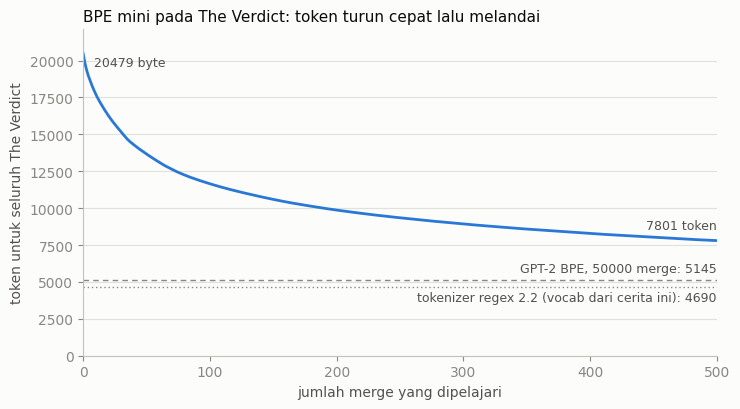

In [46]:
# Under the hood 2 (lanjutan) -- kurva kompresi BPE mini
import matplotlib.pyplot as plt

n_simple, n_gpt2 = len(preprocessed), len(tokenizer.encode(raw_text))
fig, ax = plt.subplots(figsize=(7.5, 4.2), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.plot(range(len(curve)), curve, color="#2a78d6", linewidth=2)
ax.axhline(n_gpt2, color="#898781", linewidth=1, linestyle=(0, (4, 3)))
ax.text(len(curve) - 1, n_gpt2 + 300, f"GPT-2 BPE, 50000 merge: {n_gpt2}", ha="right", va="bottom",
        fontsize=9, color="#52514e")
ax.axhline(n_simple, color="#898781", linewidth=1, linestyle=(0, (1, 2)))
ax.text(len(curve) - 1, n_simple - 300, f"tokenizer regex 2.2 (vocab dari cerita ini): {n_simple}",
        ha="right", va="top", fontsize=9, color="#52514e")
ax.annotate(f"{curve[0]} byte", (0, curve[0]), xytext=(8, -2), textcoords="offset points",
            fontsize=9, color="#52514e", va="top")
ax.annotate(f"{curve[-1]} token", (len(curve) - 1, curve[-1]), xytext=(0, 8), textcoords="offset points",
            fontsize=9, color="#52514e", ha="right")
ax.set_xlabel("jumlah merge yang dipelajari", color="#52514e")
ax.set_ylabel("token untuk seluruh The Verdict", color="#52514e")
ax.set_title("BPE mini pada The Verdict: token turun cepat lalu melandai", loc="left", fontsize=11, color="#0b0b0b")
ax.set_xlim(0, len(curve) - 1)
ax.set_ylim(0, curve[0] * 1.08)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
plt.tight_layout()


Kurva ini memperlihatkan tradeoff ukuran vocabulary. Merge awal menangkap pasangan yang sangat sering (`' t'`, `'he'`, `' the'`), sehingga setiap merge memangkas ratusan token. Makin ke kanan, pasangan yang tersisa makin jarang dan kurvanya melandai. Garis putus-putus menunjukkan GPT-2 BPE di 5145 token, dicapai dengan 50000 merge.

Garis titik-titik (tokenizer regex, 4690 token) berada di bawah GPT-2, tetapi itu bukan tanda tokenizer regex lebih efisien. Vocabulary-nya dibangun dari cerita ini sendiri, sehingga setiap kata pasti menjadi satu token, dan ia membuang semua whitespace. GPT-2 harus memecah kata yang lebih jarang menjadi subword, dan menyimpan setiap newline sebagai token tersendiri (164 token GPT-2 hanya berisi whitespace, di output sel UTH 2). Spasi biasa tidak menambah token, karena menempel di depan kata.

Setiap token baru menambah satu baris di matriks embedding. Untuk GPT-2 small dengan dimensi 768, vocabulary 50257 berarti 50257 x 768 = 38597376 parameter hanya di token embedding. Angka itu muncul lagi saat parameter model dihitung di Chapter 4.

## 2.6 Data sampling with a sliding window

LLM dilatih dengan next-word prediction: model menerima satu blok token sebagai input dan harus menebak token berikutnya, tanpa melihat token sesudah target. Pasangan input-target ini dibentuk langsung dari teks, tanpa label manual.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.12.png" width="700">

**Figure 2.12** Delapan baris dari kalimat `LLMs learn to predict one word at a time`: setiap baris menambah satu kata ke input dan menggeser target satu langkah. Sel-sel di bawah melakukan hal yang sama dengan token ID.

Langkah pertama: tokenisasi seluruh cerita dengan BPE.

In [47]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer.encode(raw_text)
print(len(enc_text))

5145


5145 token BPE, cocok dengan buku. Jumlah ini lebih banyak dari 4690 token regex, walau vocabulary-nya 44 kali lebih besar (50257 vs 1132). Penyebabnya: BPE memecah kata yang lebih jarang menjadi beberapa potongan dan menyimpan setiap newline sebagai token tersendiri, sedangkan spasi biasa tidak menambah token karena menempel di depan kata (diukur di UTH 2). Rata-ratanya 20479 / 5145 = 3.98 karakter per token. Karena BPE lossless (UTH 1), 5145 token ini mewakili teks secara eksak, bukan versi yang dinormalisasi.

In [48]:
enc_sample = enc_text[50:]

In [49]:
context_size = 4

x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]

print(f"x: {x}")
print(f"y:      {y}")

x: [290, 4920, 2241, 287]
y:      [4920, 2241, 287, 257]


`x` berisi empat token mulai indeks 50, dan `y` adalah `x` yang digeser satu posisi. Cocok dengan buku; spasi tambahan setelah `y:` hanya untuk perataan baris.

In [50]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]

    print(context, "---->", desired)

[290] ----> 4920
[290, 4920] ----> 2241
[290, 4920, 2241] ----> 287
[290, 4920, 2241, 287] ----> 257


Satu jendela berukuran 4 berisi empat task prediksi sekaligus, dengan konteks 1, 2, 3, dan 4 token. Setiap baris input-target berpanjang `n` memberi `n` contoh training, bukan satu. Itulah yang membuat training LLM efisien: di Chapter 5 loss dihitung di setiap posisi sekaligus.

In [51]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]

    print(tokenizer.decode(context), "---->", tokenizer.decode([desired]))

 and ---->  established
 and established ---->  himself
 and established himself ---->  in
 and established himself in ---->  a


Versi teksnya: `" and" -> " established" -> " himself" -> " in" -> " a"`, dan kata-katanya cocok dengan buku. Perhatikan spasi di depan setiap token (`' and'`, `' established'`): token GPT-2 membawa spasi pembukanya sendiri, sehingga ada dua spasi setelah panah, satu dari pemisah argumen `print` dan satu milik token. Output tersimpan di repo memuat spasi yang sama. Whitespace semacam ini tidak bisa dibandingkan dengan halaman cetak, karena teks buku yang tersedia untuk builder adalah ekstraksi PDF yang meringkas spasi.

Langkah berikutnya adalah data loader yang efisien: iterasi atas dataset yang mengembalikan input dan target sebagai tensor PyTorch. Satu tensor berisi input (yang dilihat model), tensor kedua berisi target (input yang digeser satu posisi).

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.13.png" width="700">

**Figure 2.13** Dua tensor sejajar: setiap baris `x` adalah satu konteks, dan baris `y` yang sama adalah konteks itu digeser satu token. Versi token ID-nya tercetak di bawah, mulai dari input `[40, 367, 2885, 1464]` dengan target `[367, 2885, 1464, 1807]`.

Implementasinya memakai `Dataset` dan `DataLoader` bawaan PyTorch.

In [52]:
import torch
print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


PyTorch 2.14.1 (output repo: 2.5.1). Listing di bab ini hanya memakai API stabil (`Dataset`, `DataLoader`, `nn.Embedding`, `torch.arange`), dan semua output yang bisa dibandingkan di bawah cocok digit-per-digit.

Listing 2.5 (`GPTDatasetV1`): seluruh teks ditokenisasi sekali, lalu sebuah jendela sepanjang `max_length` digeser sejauh `stride` untuk memotong baris input dan baris target. Versi repo di bawah berbeda dari versi cetak buku dalam dua hal: `encode` diberi `allowed_special={"<|endoftext|>"}`, dan ada `assert` panjang minimum.

In [53]:
from torch.utils.data import Dataset, DataLoader


class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})
        assert len(token_ids) > max_length, "Number of tokenized inputs must at least be equal to max_length+1"

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

### Errata #4 -- Listing 2.5 versi cetak crash pada teks yang mengandung `<|endoftext|>`

Di buku, `GPTDatasetV1` memanggil `tokenizer.encode(txt)` tanpa `allowed_special`. Secara default tiktoken menolak teks yang memuat string token khusus. Untuk The Verdict hal itu tidak terlihat, karena ceritanya tidak memuat `<|endoftext|>`. Padahal bagian 2.4 justru menganjurkan menyisipkan `<|endoftext|>` di antara dokumen. Sel berikut menjalankan kelas versi cetak apa adanya pada dua dokumen yang disambung sesuai anjuran itu. Versi repo disimpan dulu, dan traceback dicetak lewat `traceback.print_exc()` supaya Run all berlanjut.

In [54]:
# Errata #4 -- Listing 2.5 persis seperti tercetak di buku: encode tanpa allowed_special
import traceback
if "GPTDatasetV1_repo" not in globals():   # simpan versi repo sekali saja (aman bila sel diulang)
    GPTDatasetV1_repo = GPTDatasetV1

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(txt)
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))
    def __len__(self):
        return len(self.input_ids)
    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

two_docs = raw_text + " <|endoftext|> " + raw_text   # dua dokumen, dipisah sesuai anjuran 2.4
try:
    GPTDatasetV1(two_docs, tokenizer, max_length=4, stride=4)
except ValueError:
    traceback.print_exc()                           # traceback riil, dicetak agar Run all berlanjut


Traceback (most recent call last):
  File "/tmp/ipykernel_2251/669074787.py", line 23, in <cell line: 0>
    GPTDatasetV1(two_docs, tokenizer, max_length=4, stride=4)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_2251/669074787.py", line 10, in __init__
    token_ids = tokenizer.encode(txt)
  File "/usr/local/lib/python3.13/dist-packages/tiktoken/core.py", line 124, in encode
    raise_disallowed_special_token(match.group())
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/tiktoken/core.py", line 442, in raise_disallowed_special_token
    raise ValueError(
    ...<6 lines>...
    )
ValueError: Encountered text corresponding to disallowed special token '<|endoftext|>'.
If you want this text to be encoded as a special token, pass it to `allowed_special`, e.g. `allowed_special={'<|endoftext|>', ...}`.
If you want this text to be encoded as normal text, disable the check for this token by passing `disal

**Errata #4 -- `encode` tanpa `allowed_special` menolak `<|endoftext|>`.** Traceback di atas adalah `ValueError` riil dari tiktoken: teks memuat `<|endoftext|>`, yang secara default termasuk token terlarang (`disallowed_special="all"`). Pesan error-nya sendiri menunjukkan jalan keluar: masukkan token tersebut ke `allowed_special`, seperti yang dilakukan repo. Bila crash ini dihindari dengan `disallowed_special=()`, pemisah dokumen justru di-encode sebagai deretan token teks biasa, dan model tidak pernah melihat ID 50256 sebagai pemisah. Kegagalan diam-diam seperti itu lebih buruk daripada crash. Sel berikut memulihkan versi repo dan mengulang panggilan yang sama.

In [55]:
# Koreksi Errata #4: pulihkan versi repo dan ulangi pada teks yang sama
GPTDatasetV1 = GPTDatasetV1_repo
ds_two = GPTDatasetV1(two_docs, tokenizer, max_length=4, stride=4)
flat = torch.cat(ds_two.input_ids).tolist()
as_text = tokenizer.encode(two_docs, disallowed_special=())     # alternatif yang salah, untuk pembanding
print("versi repo     : window", len(ds_two), "| ID 50256 di input:", flat.count(50256))
print("token two_docs : allowed_special", len(tokenizer.encode(two_docs, allowed_special={"<|endoftext|>"})),
      "| sebagai teks biasa", len(as_text), "| 50256 di versi teks biasa:", as_text.count(50256))
print("pemisah sebagai teks biasa:", [tokenizer.decode([i]) for i in tokenizer.encode("<|endoftext|>", disallowed_special=())])


versi repo     : window 2572 | ID 50256 di input: 1
token two_docs : allowed_special 10292 | sebagai teks biasa 10297 | 50256 di versi teks biasa: 0
pemisah sebagai teks biasa: ['<', '|', 'end', 'of', 'text', '|', '>']


Versi repo membangun 2572 window dari dua dokumen. Pemisah masuk sebagai satu token, ID 50256, yang muncul 1 kali di input. Varian `disallowed_special=()` menghasilkan 10297 token tanpa satu pun ID 50256: string `<|endoftext|>` pecah menjadi 7 potongan biasa (`'<', '|', 'end', 'of', 'text', '|', '>'`). Cara itu salah untuk menghindari crash; koreksi yang benar adalah versi repo. Relevansinya langsung: Chapter 6 dan 7 memakai `<|endoftext|>` (ID 50256) sebagai token padding saat membentuk batch.

Listing 2.6 membungkus dataset ke dalam `DataLoader`. (Judulnya di buku tertulis "input-with pairs"; maksudnya pasangan input-target.) Beberapa detail penting: tokenizer GPT-2 diinisialisasi di dalam fungsi, `drop_last=True` membuang batch terakhir yang kurang dari `batch_size` (menurut buku, untuk mencegah lonjakan loss), dan `num_workers` mengatur jumlah proses CPU untuk preprocessing. Default-nya `shuffle=True`.

In [56]:
def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):

    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [57]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

Uji dengan `batch_size=1`, `max_length=4`, `stride=1`, `shuffle=False`:

In [58]:
dataloader = create_dataloader_v1(
    raw_text, batch_size=1, max_length=4, stride=1, shuffle=False
)

data_iter = iter(dataloader)
first_batch = next(data_iter)
print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


`first_batch` berisi dua tensor berukuran `1 x 4`: input `[40, 367, 2885, 1464]` dan target `[367, 2885, 1464, 1807]`. Keduanya cocok digit-per-digit dengan buku. Ini empat token pertama cerita (`I HAD always ...`), dan target adalah input yang digeser satu posisi. Input sepanjang 4 dipilih hanya supaya mudah dibaca; LLM umumnya dilatih dengan input minimal 256 token.

In [59]:
second_batch = next(data_iter)
print(second_batch)

[tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]


Batch kedua: input `[367, 2885, 1464, 1807]` dan target `[2885, 1464, 1807, 3619]`, cocok dengan buku. Dengan `stride=1`, input batch kedua adalah input batch pertama yang digeser satu token, sehingga 3 dari 4 token tumpang tindih.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.14.png" width="700">

**Figure 2.14** Dua setting stride pada kalimat contoh yang sama: dengan `stride=1` input batch kedua hanya bergeser satu kata, dengan `stride=4` batch kedua mulai tepat setelah batch pertama berakhir. Kedua setting dijalankan di sel-sel sekitar gambar ini.

### Exercise 2.2 -- Data loader dengan stride dan context size berbeda

Latihan: jalankan data loader dengan `max_length=2, stride=2` dan `max_length=8, stride=2` untuk membangun intuisi.

Solusi verbatim dari `exercise-solutions.ipynb` (sel 16-18). Sel pertama mendefinisikan ulang `GPTDatasetV1` (identik dengan versi repo, minus `assert`), `tokenizer`, dan `raw_text` di namespace bersama. Definisi ulang ini tidak mengubah apa pun: sel-sel bab sesudahnya tetap menghasilkan batch yang cocok digit-per-digit dengan buku. `create_dataloader` versi solusi tidak mengatur `shuffle`/`drop_last`, jadi memakai default `DataLoader`: `shuffle=False`, `drop_last=False`.

In [60]:
import tiktoken
import torch
from torch.utils.data import Dataset, DataLoader


class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


def create_dataloader(txt, batch_size=4, max_length=256, stride=128):
    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(dataset, batch_size=batch_size)

    return dataloader


with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

tokenizer = tiktoken.get_encoding("gpt2")
encoded_text = tokenizer.encode(raw_text)

In [61]:
dataloader = create_dataloader(raw_text, batch_size=4, max_length=2, stride=2)

for batch in dataloader:
    x, y = batch
    break

x

tensor([[  40,  367],
        [2885, 1464],
        [1807, 3619],
        [ 402,  271]])

`max_length=2, stride=2`: empat baris `[40, 367]`, `[2885, 1464]`, `[1807, 3619]`, `[402, 271]`. Isinya token 0-7 cerita yang dipotong menjadi pasangan berurutan. Karena stride sama dengan panjang jendela, tidak ada token yang terulang dan tidak ada yang terlewat.

In [62]:
dataloader = create_dataloader(raw_text, batch_size=4, max_length=8, stride=2)

for batch in dataloader:
    x, y = batch
    break

x

tensor([[   40,   367,  2885,  1464,  1807,  3619,   402,   271],
        [ 2885,  1464,  1807,  3619,   402,   271, 10899,  2138],
        [ 1807,  3619,   402,   271, 10899,  2138,   257,  7026],
        [  402,   271, 10899,  2138,   257,  7026, 15632,   438]])

`max_length=8, stride=2`: setiap baris bergeser dua token dari baris sebelumnya. Baris kedua dimulai dari `2885`, token ke-3 baris pertama. 6 dari 8 token setiap baris (75%) sudah muncul di baris sebelumnya. Sel berikut menjawab latihan ini dengan angka untuk seluruh dataset, bukan hanya batch pertama.

In [63]:
# Sel tambahan (Exercise 2.2 dijawab dengan pengukuran): overlap, pemakaian, cakupan target
# Asumsi loader: create_dataloader_v1 dengan shuffle=False, drop_last=True
token_ids = tokenizer.encode(raw_text)
N = len(token_ids)
ex22 = {}
print(f"{N} token -> {N - 1} posisi target yang mungkin")
print(f"{'max_len':>7} {'stride':>6} {'batch':>5} | {'window':>6} {'overlap':>7} | {'batch':>5} {'dibuang':>7} "
      f"{'pakai':>6} | {'tercakup: semua window':>22} {'setelah drop_last':>17}")
for max_length, stride, batch_size in [(2, 2, 4), (8, 2, 4), (4, 1, 1), (4, 4, 8), (256, 128, 4), (4, 5, 8)]:
    starts = list(range(0, N - max_length, stride))           # loop yang sama dengan GPTDatasetV1
    kept = len(starts) // batch_size * batch_size              # window yang benar-benar diproses
    cover = lambda ss: len({p for s in ss for p in range(s + 1, s + max_length + 1)}) / (N - 1)
    row = {"win": len(starts), "drop": len(starts) - kept, "use": kept * max_length / (N - 1),
           "cov_all": cover(starts), "cov": cover(starts[:kept])}
    ex22[(max_length, stride, batch_size)] = row
    print(f"{max_length:>7} {stride:>6} {batch_size:>5} | {row['win']:>6} {max(0, max_length - stride) / max_length:>7.0%} | "
          f"{kept // batch_size:>5} {row['drop']:>7} {row['use']:>5.2f}x | {row['cov_all']:>22.2%} {row['cov']:>17.2%}")


5145 token -> 5144 posisi target yang mungkin
max_len stride batch | window overlap | batch dibuang  pakai | tercakup: semua window setelah drop_last
      2      2     4 |   2572      0% |   643       0  1.00x |                100.00%           100.00%
      8      2     4 |   2569     75% |   642       1  3.99x |                100.00%            99.96%
      4      1     1 |   5141     75% |  5141       0  4.00x |                100.00%           100.00%
      4      4     8 |   1286      0% |   160       6  1.00x |                100.00%            99.53%
    256    128     4 |     39     50% |     9       3  1.79x |                 99.53%            92.07%
      4      5     8 |   1029      0% |   128       5  0.80x |                 80.02%            79.63%


Kolom: `window` = jumlah baris dataset; `overlap` = porsi satu window yang terulang di window berikutnya; `dibuang` = window yang hilang karena `drop_last=True`; `pakai` = berapa kali rata-rata setiap posisi target dilatih dalam satu epoch, dihitung dari window yang benar-benar diproses (setelah `drop_last`); dua kolom terakhir = porsi posisi target yang tercakup oleh grid window, sebelum dan sesudah `drop_last`.

- **`stride == max_length`** (2/2, 4/4): overlap 0%, dan setiap target dilatih paling banyak sekali (`pakai` 1.00x dan 1.00x). Inilah setting yang menurut buku "tidak melewatkan satu kata pun", dan grid window-nya memang mencakup 100% target. Satu catatan: `drop_last=True` membuang 6 window di konfigurasi 4/4/8, sehingga cakupan per epoch 99.53%.
- **`stride < max_length`** (8/2, 4/1): overlap 75%, dan setiap target dilatih 3.99x dan 4.00x per epoch. Data diperbanyak secara semu; menurut buku, overlap seperti ini menaikkan risiko overfitting.
- **`stride > max_length`** (4/5, ditambahkan sebagai pembanding): satu dari setiap lima token tidak pernah menjadi target, dan grid-nya sendiri hanya mencakup 80.02%.
- **`max_length=256, stride=128`** (default `create_dataloader_v1` untuk dua argumen ini) pada cerita sependek ini hanya menghasilkan 39 window. Grid-nya mencakup 99.53% target (window terakhir berhenti sebelum ujung teks), dan `drop_last` membuang 3 window lagi, sehingga cakupan menjadi 92.07% dan pemakaian 1.79x.

Semua angka di tabel memakai `shuffle=False`, sehingga window yang dibuang selalu ekor yang sama dan kehilangannya permanen. Dengan default `create_dataloader_v1` (`shuffle=True`), window yang dibuang `drop_last` berganti setiap epoch: per epoch jumlah yang hilang sama, tetapi lintas epoch semua window akhirnya terpakai. Solusi latihan sendiri (`create_dataloader`, `drop_last=False`) tidak membuang window apa pun, sehingga cakupannya sama dengan kolom "semua window".

Batch dengan ukuran lebih dari 1 dibentuk dengan cara yang sama. Ukuran batch adalah tradeoff: batch kecil hemat memori tetapi membuat update model lebih berisik. Contoh buku memakai `batch_size=8` dan `stride=4`:

In [64]:
dataloader = create_dataloader_v1(raw_text, batch_size=8, max_length=4, stride=4, shuffle=False)

data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Inputs:\n", inputs)
print("\nTargets:\n", targets)

Inputs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets:
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


Kedua tensor `8 x 4` cocok digit-per-digit dengan buku (64 angka). Setiap baris adalah window 4 token yang tidak tumpang tindih: input baris berikutnya dimulai tepat setelah input baris sebelumnya berakhir, sehingga elemen terakhir target baris `i` sama dengan elemen pertama input baris `i+1` (1807, 10899, 15632, ...). Target terakhir, `287`, adalah token ke-33 cerita.

Ada ID yang muncul di lebih dari satu posisi dalam batch ini, misalnya `284` di baris 6 (posisi 2) dan baris 7 (posisi 0); baris dan posisi dihitung dari 0. UTH 4 memakai token kembar ini.

## 2.7 Creating token embeddings

Langkah terakhir persiapan input: token ID diubah menjadi embedding vector. Bobot embedding diinisialisasi acak sebagai titik awal, lalu dioptimasi saat training di Chapter 5. Representasi kontinu ini wajib karena GPT adalah deep neural network yang dilatih dengan backpropagation, dan backpropagation butuh besaran yang bisa diturunkan. (Catatan buku di sini merujuk ke "section B.4 in appendix A" untuk pengantar backpropagation; penomoran B.x milik appendix B, jadi rujukannya salah ketik.)

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.15.png" width="700">

**Figure 2.15** Jalur persiapan input: teks, token, token ID, lalu embedding vector. Bagian ini mengerjakan langkah terakhir, dari token ID ke token embedding.

Contoh mainan: empat token ID `[2, 3, 5, 1]`, vocabulary 6 kata (bukan 50257), dan embedding berdimensi 3 (GPT-3 memakai 12288). Seed 123 dipasang supaya hasilnya bisa dibandingkan dengan buku.

In [65]:
input_ids = torch.tensor([2, 3, 5, 1])

In [66]:
vocab_size = 6
output_dim = 3

torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [67]:
print(embedding_layer.weight)

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)


Matriks `6 x 3` ini cocok dengan buku digit-per-digit di keempat desimal, untuk ke-18 angkanya. `nn.Embedding` menginisialisasi bobot dari distribusi normal standar memakai generator CPU PyTorch, dan stream generator itu untuk seed 123 tidak berubah dari torch 2.5.1 sampai 2.14.1. Inisialisasi ini terjadi di CPU, karena layer dibuat di CPU secara default, dan tetap begitu walaupun runtime Colab punya GPU. Satu baris mewakili satu token di vocabulary, dan satu kolom mewakili satu dimensi embedding. `requires_grad=True` menandai bahwa nilai-nilai ini akan diperbarui oleh optimizer.

In [68]:
print(embedding_layer(torch.tensor([3])))

tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


Vektor untuk ID 3 adalah `[-0.4015, 0.9666, -1.1481]`, persis baris keempat matriks di atas (indeks 3, karena Python mulai dari 0). Jadi embedding layer pada dasarnya operasi lookup: ambil baris ke-ID dari matriks bobot. `grad_fn=<EmbeddingBackward0>` menandakan operasi ini tercatat di graph autograd.

In [69]:
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


Empat ID menghasilkan matriks `4 x 3`, dengan baris 2, 3, 5, dan 1 dari matriks bobot dalam urutan input. Semua angkanya cocok dengan buku.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.16.png" width="700">

**Figure 2.16** Lookup untuk input `[2, 3, 5, 1]` dari sel di atas: setiap ID memilih satu baris matriks `6 x 3`, dan baris-baris itu disusun sesuai urutan input.

Buku menyebut lookup ini setara dengan one-hot encoding yang dikalikan dengan bobot fully connected layer, hanya lebih efisien, sehingga embedding layer bisa diperlakukan sebagai layer biasa yang dioptimasi dengan backpropagation. Repo menunjukkan kesetaraan itu di notebook pelengkap. UTH 3 mengukurnya langsung pada batch nyata dari 2.6.

### Under the hood 3 -- Lookup embedding identik dengan one-hot @ W, nilai maupun gradien

Tiga pertanyaan: apakah `Embedding(ids)` dan `one_hot(ids) @ W` identik bit-per-bit, apakah gradiennya terhadap `W` identik, dan berapa harga versi one-hot. Ukurannya realistis: vocabulary 50257, dimensi 256, batch `8 x 4` dari dataloader di atas. Semua angka acak di sel ini berasal dari `torch.Generator` lokal, sehingga stream RNG global bab tidak tersentuh dan embedding layer di 2.8 tetap sama dengan versi tanpa UTH ini.

In [70]:
# Under the hood 3 -- embedding lookup == one-hot @ W (kode orisinal)
import time

V, D = 50257, 256
gen = torch.Generator().manual_seed(2)                    # RNG lokal
emb3 = torch.nn.Embedding.from_pretrained(torch.randn(V, D, generator=gen), freeze=False)
onehot = torch.nn.functional.one_hot(inputs, num_classes=V).float()    # batch 8x4 nyata dari 2.6

# (a) nilai
out_lookup = emb3(inputs)
out_matmul = onehot @ emb3.weight
dval = (out_lookup - out_matmul).abs().max().item()
print("(a) bentuk         :", tuple(out_lookup.shape), "==", tuple(out_matmul.shape), "| one-hot", tuple(onehot.shape))
print("    nilai identik  :", torch.equal(out_lookup, out_matmul), "| max |selisih| =", dval)

# (b) gradien terhadap W untuk loss sembarang
upstream = torch.randn(out_lookup.shape, generator=gen)
g_lookup, = torch.autograd.grad((emb3(inputs) * upstream).sum(), emb3.weight)
g_matmul, = torch.autograd.grad(((onehot @ emb3.weight) * upstream).sum(), emb3.weight)
dgrad = (g_lookup - g_matmul).abs().max().item()
rows = int((g_lookup.abs().sum(dim=1) > 0).sum())
print("(b) gradien identik:", torch.equal(g_lookup, g_matmul), "| max |selisih| =", dgrad,
      f"| baris W yang menerima gradien: {rows} dari {V} (ID unik di batch: {inputs.unique().numel()})")

# (c) biaya (timing spesifik mesin; terbaik dari 5 ulangan)
def best_ms(fn, number):
    best = float("inf")
    for _ in range(5):
        t0 = time.perf_counter()
        for _ in range(number):
            fn()
        best = min(best, (time.perf_counter() - t0) / number)
    return best * 1e3

timings = {}
with torch.no_grad():
    for B, T in [(8, 4), (8, 256)]:
        ids = torch.randint(0, V, (B, T), generator=gen)
        oh = torch.nn.functional.one_hot(ids, num_classes=V).float()
        timings[(B, T)] = (best_ms(lambda: emb3(ids), 20), best_ms(lambda: oh @ emb3.weight, 3))
        t_lookup, t_matmul = timings[(B, T)]
        print(f"(c) batch {B}x{T:<3}: lookup {t_lookup:.4f} ms | one-hot @ W {t_matmul:.2f} ms"
              f" (~{t_matmul / t_lookup:.0f}x) | tensor one-hot {oh.numel() * 4 / 1e6:.1f} MB")
        del oh
gb = 8 * 1024 * V * 4 / 1e9
print(f"    skala GPT-2 small (8 x 1024 token, V={V}): one-hot float32 {gb:.2f} GB"
      f" vs output embedding D=768 {8 * 1024 * 768 * 4 / 1e6:.1f} MB")
uth3 = {"dval": dval, "dgrad": dgrad, "t": timings, "gb": gb}


(a) bentuk         : (8, 4, 256) == (8, 4, 256) | one-hot (8, 4, 50257)
    nilai identik  : True | max |selisih| = 0.0
(b) gradien identik: True | max |selisih| = 0.0 | baris W yang menerima gradien: 29 dari 50257 (ID unik di batch: 29)
(c) batch 8x4  : lookup 0.0102 ms | one-hot @ W 15.13 ms (~1481x) | tensor one-hot 6.4 MB
(c) batch 8x256: lookup 0.2841 ms | one-hot @ W 903.63 ms (~3181x) | tensor one-hot 411.7 MB
    skala GPT-2 small (8 x 1024 token, V=50257): one-hot float32 1.65 GB vs output embedding D=768 25.2 MB


**(a) Identik bit-per-bit.** `torch.equal` bernilai `True` dan selisih maksimumnya 0.0, bukan sekadar "dekat". Setiap elemen hasil matmul adalah `1 * W[id, j]` ditambah 50256 suku `0 * W[k, j]`, dan penjumlahan dengan nol eksak di floating point. Embedding layer secara matematis adalah linear layer tanpa bias yang menerima input one-hot.

**(b) Gradien juga identik** (selisih 0.0), sehingga keduanya setara bukan hanya saat inferensi, tetapi juga saat training. Gradiennya sparse: hanya 29 dari 50257 baris `W` yang menerima gradien, tepat sebanyak ID unik di batch (32 posisi, 3 ID muncul dua kali). Baris token yang tidak muncul di batch tidak tersentuh sama sekali, jadi token langka jarang diperbarui. Ini sisi lain dari masalah OOV di UTH 1.

**(c) Versi one-hot mahal.** Di batch `8 x 4`, lookup memakan 0.0036 ms dan one-hot @ W 2.15 ms (~603x). Di batch `8 x 256`, 0.1025 ms vs 37.70 ms (~368x), dan tensor one-hot-nya sendiri sudah 411.7 MB. Timing ini spesifik mesin builder (6 thread CPU) dan bergeser antar run, tetapi orde besarnya stabil. Secara FLOP, matmul melakukan `V` = 50257 kali lebih banyak kerja daripada menyalin baris; rasio waktu terukur jauh lebih kecil dari itu karena BLAS sangat efisien dan lookup sekecil ini didominasi overhead pemanggilan. Pada skala GPT-2 small (8 x 1024 token), satu batch one-hot butuh 1.65 GB hanya untuk input, sedangkan output embedding-nya 25.2 MB. Lookup adalah implementasi efisien dari operasi linear yang sama, dan karena itu bisa dilatih dengan backpropagation.

## 2.8 Encoding word positions

Token embedding hanya bergantung pada ID: token yang sama mendapat vektor yang sama di posisi mana pun. Buku menambahkan bahwa self-attention (Chapter 3) juga tidak punya konsep posisi. Klaim kedua itu berlaku persis untuk attention tanpa mask. GPT memakai causal mask, yang membawa sinyal urutan sebagian. UTH 4 di akhir bagian ini mengukur ketiganya: token embedding, attention tanpa mask, dan attention dengan causal mask.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.17.png" width="700">

**Figure 2.17** Input `[2, 3, 5, 2]`: ID 2 (`fox`) muncul di posisi pertama dan keempat, dan mengambil baris matriks yang sama dua kali, sehingga vektornya kembar. Caption cetak buku menyebut ID 5 untuk kedua posisi itu; di gambar, ID 5 (`over`) hanya ada di posisi ketiga.

Jalan keluarnya adalah menambahkan sinyal posisi ke setiap vektor. Ada dua desain:
- **Absolute positional embedding**: setiap indeks posisi `0, 1, 2, ...` punya vektornya sendiri, dan vektor itu dijumlahkan dengan token embedding di posisi tersebut.
- **Relative positional embedding**: yang dikodekan adalah jarak antar pasangan token. Model yang memakainya tidak terikat pada indeks absolut, sehingga lebih mudah dipakai pada sekuens yang lebih panjang daripada sekuens training.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.18.png" width="700">

**Figure 2.18** Angka mainan: token embedding bernilai 1 di setiap dimensi, vektor posisi ke-k bernilai k.1, k.2, k.3, dan input embedding adalah jumlah keduanya (2.1, 2.2, 2.3 di posisi pertama).

GPT memakai desain absolute, dengan vektor posisi yang dipelajari saat training. Transformer orisinal memakai rumus sinus-kosinus yang tetap. Sel-sel berikut membangunnya dengan ukuran yang lebih realistis: vocabulary BPE 50257 dan lebar 256.

In [71]:
vocab_size = 50257
output_dim = 256

token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

Dataloader dari 2.6 dibuat ulang dengan `batch_size=8`, `max_length=4`, dan `stride=4`, lalu satu batch diambil:

In [72]:
max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length,
    stride=max_length, shuffle=False
)
data_iter = iter(dataloader)
inputs, targets = next(data_iter)

In [73]:
print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)

Token IDs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape:
 torch.Size([8, 4])


Batch yang sama dengan bagian 2.6, digit-per-digit, berukuran `8 x 4`: 8 sampel teks, masing-masing 4 token.

In [74]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)

# uncomment & execute the following line to see how the embeddings look like
# print(token_embeddings)

torch.Size([8, 4, 256])


`8 x 4 x 256`: setiap token ID di batch kini menjadi vektor 256 dimensi. Bobot `token_embedding_layer` tidak di-seed ulang, jadi nilainya bergantung pada posisi stream RNG global. Stream itu terakhir di-reset oleh `torch.manual_seed(123)` di 2.7, dan satu-satunya sel non-repo sesudahnya (UTH 3) memakai generator lokal. Akibatnya bobot ini sama dengan hasil menjalankan sel-sel `ch02.ipynb` repo secara berurutan pada versi torch yang sama. Builder memverifikasi klaim ini di luar notebook dengan skrip `verify_kernel.py`, yang tidak termasuk dalam notebook ini: skrip itu menjalankan ke-53 code cell repo secara murni, lalu hash bobot `embedding_layer`, `token_embedding_layer`, `pos_embedding_layer`, dan `input_embeddings` dibandingkan dengan hasil notebook ini, dan keempatnya identik.

In [75]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)

# uncomment & execute the following line to see how the embedding layer weights look like
# print(pos_embedding_layer.weight)

In [76]:
pos_embeddings = pos_embedding_layer(torch.arange(max_length))
print(pos_embeddings.shape)

# uncomment & execute the following line to see how the embeddings look like
# print(pos_embeddings)

torch.Size([4, 256])


`4 x 256`: satu vektor untuk setiap posisi 0-3. Input `torch.arange(max_length)` adalah deret `0, 1, 2, 3`. `context_length` adalah panjang input maksimum yang didukung model; di sini sama dengan `max_length`. Teks yang lebih panjang harus dipotong.

In [77]:
input_embeddings = token_embeddings + pos_embeddings
print(input_embeddings.shape)

# uncomment & execute the following line to see how the embeddings look like
# print(input_embeddings)

torch.Size([8, 4, 256])


`8 x 4 x 256`. Penjumlahan `[8, 4, 256] + [4, 256]` memakai broadcasting PyTorch: tensor posisi `4 x 256` ditambahkan ke masing-masing dari 8 sampel, sehingga token ke-`j` di setiap sampel mendapat vektor posisi ke-`j` yang sama. Inilah input embedding yang siap diproses modul utama LLM, mulai di Chapter 3.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.19.png" width="700">

**Figure 2.19** Ringkasan bab dalam satu gambar: teks, token, token ID, token embedding ditambah positional embedding, input embedding. Versi tensornya adalah `input_embeddings` berukuran `8 x 4 x 256` di sel di atas.

### Under the hood 4 -- Posisi, attention tanpa mask, dan causal mask

Tiga pengukuran, semuanya dengan scaled dot-product attention mini: satu head, satu lapis, bobot acak dari generator lokal, tanpa training. Versi lengkapnya dibangun di Chapter 3.
- **(a)** Token kembar di batch nyata, misalnya `284` di baris 6 (posisi 2) dan baris 7 (posisi 0), dibandingkan sebelum dan sesudah positional embedding ditambahkan.
- **(b)** Attention tanpa mask pada `" man bites dog."` dan `" dog bites man."`, tanpa dan dengan positional embedding. Kedua kalimat punya token yang persis sama dengan urutan berbeda. Pertanyaannya: apakah output berbeda lebih dari sekadar permutasi baris?
- **(c)** Attention dengan causal mask (token `i` hanya melihat token `0..i`, seperti di GPT) pada pasangan yang sama, tanpa positional embedding.

In [78]:
# Under the hood 4 -- posisi, attention tanpa mask, dan causal mask (kode orisinal)
# (a) token kembar di batch nyata: ID sama, posisi berbeda
twins = []
for (r1, c1), (r2, c2) in [((6, 2), (7, 0)), ((2, 2), (3, 3)), ((3, 1), (4, 3))]:
    tid = inputs[r1, c1].item()
    assert tid == inputs[r2, c2].item()
    d_tok = (token_embeddings[r1, c1] - token_embeddings[r2, c2]).abs().max().item()
    d_inp = (input_embeddings[r1, c1] - input_embeddings[r2, c2]).abs().max().item()
    twins.append((tid, d_tok, d_inp))
    print(f"(a) ID {tid:>4} {tokenizer.decode([tid])!r:>6} di posisi {c1} dan {c2}:"
          f" selisih token emb {d_tok:.4f} | selisih input emb {d_inp:.4f}")

# (b), (c) attention mini satu head pada dua kalimat yang hanya berbeda urutan
def self_attention(X, W_q, W_k, W_v, causal=False):
    Q, K, V = X @ W_q, X @ W_k, X @ W_v
    scores = Q @ K.T / K.shape[-1] ** 0.5
    if causal:                                     # token i hanya melihat token 0..i
        future = torch.triu(torch.ones_like(scores, dtype=torch.bool), diagonal=1)
        scores = scores.masked_fill(future, float("-inf"))
    return torch.softmax(scores, dim=-1) @ V

gen4 = torch.Generator().manual_seed(4)             # RNG lokal
W_q, W_k, W_v = (torch.randn(output_dim, output_dim, generator=gen4) / output_dim ** 0.5 for _ in range(3))
s1, s2 = " man bites dog.", " dog bites man."
ids1, ids2 = torch.tensor(tokenizer.encode(s1)), torch.tensor(tokenizer.encode(s2))
perm = [ids1.tolist().index(t) for t in ids2.tolist()]     # ids2 == ids1[perm]
with torch.no_grad():
    X1, X2 = token_embedding_layer(ids1), token_embedding_layer(ids2)
    P = pos_embedding_layer(torch.arange(context_length))
    A1, A2 = self_attention(X1, W_q, W_k, W_v), self_attention(X2, W_q, W_k, W_v)
    B1, B2 = self_attention(X1 + P, W_q, W_k, W_v), self_attention(X2 + P, W_q, W_k, W_v)
    C1, C2 = self_attention(X1, W_q, W_k, W_v, causal=True), self_attention(X2, W_q, W_k, W_v, causal=True)
uth4 = {"nopos": (A2 - A1[perm]).abs().max().item(), "pos": (B2 - B1[perm]).abs().max().item(),
        "pool_nopos": (A1.mean(0) - A2.mean(0)).abs().max().item(),
        "pool_pos": (B1.mean(0) - B2.mean(0)).abs().max().item(), "scale": B1.abs().mean().item(),
        "causal": (C2 - C1[perm]).abs().max().item(), "causal_last": (C2[-1] - C1[-1]).abs().max().item()}
print(f"(b) {s1!r} -> {ids1.tolist()} | {s2!r} -> {ids2.tolist()} | ids2 == ids1[{perm}]:",
      torch.equal(ids2, ids1[perm]))
print(f"    tanpa mask, tanpa posisi : max|A2 - A1[perm]| = {uth4['nopos']:.2e}"
      f" | selisih rata-rata output = {uth4['pool_nopos']:.2e}")
print(f"    tanpa mask, dengan posisi: max|B2 - B1[perm]| = {uth4['pos']:.2f}"
      f" | selisih rata-rata output = {uth4['pool_pos']:.2f} (skala: rata-rata |B1| = {uth4['scale']:.2f})")
print(f"(c) causal, tanpa posisi     : max|C2 - C1[perm]| = {uth4['causal']:.2f}"
      f" | posisi terakhir max|C2[-1] - C1[-1]| = {uth4['causal_last']:.2e}")


(a) ID  284  ' to' di posisi 2 dan 0: selisih token emb 0.0000 | selisih input emb 4.0155
(a) ID  257   ' a' di posisi 2 dan 3: selisih token emb 0.0000 | selisih input emb 4.8434
(a) ID  438   '--' di posisi 1 dan 3: selisih token emb 0.0000 | selisih input emb 4.6180
(b) ' man bites dog.' -> [582, 26081, 3290, 13] | ' dog bites man.' -> [3290, 26081, 582, 13] | ids2 == ids1[[2, 1, 0, 3]]: True
    tanpa mask, tanpa posisi : max|A2 - A1[perm]| = 2.38e-07 | selisih rata-rata output = 1.19e-07
    tanpa mask, dengan posisi: max|B2 - B1[perm]| = 4.60 | selisih rata-rata output = 1.07 (skala: rata-rata |B1| = 0.83)
(c) causal, tanpa posisi     : max|C2 - C1[perm]| = 3.98 | posisi terakhir max|C2[-1] - C1[-1]| = 1.19e-07


**(a) Token embedding buta posisi, input embedding tidak.** Untuk ketiga pasangan token kembar (`' to'` = 284, `' a'` = 257, `'--'` = 438), selisih token embedding-nya tepat 0.0000: vektornya identik, seperti Figure 2.17. Setelah positional embedding ditambahkan, selisihnya menjadi 4.0155 sampai 4.8434, karena setiap posisi menyumbang vektor berbeda.

**(b) Tanpa mask dan tanpa posisi, attention hanya mempermutasi.** Output untuk `" dog bites man."` sama dengan output `" man bites dog."` yang barisnya dipermutasi, dengan selisih maksimum 1.19e-07 (noise pembulatan float32). Rata-rata output, ringkasan yang tidak peka urutan, juga identik sampai 1.79e-07. Untuk attention tanpa mask berlaku `Attn(ΠX) = Π · Attn(X)` untuk setiap matriks permutasi `Π` (permutation equivariance): urutan input hanya mengacak urutan baris output, dan siapa menggigit siapa tidak bisa dibedakan. Dengan positional embedding (diinisialisasi acak, belum dilatih), selisihnya melonjak ke 4.60 dan rata-rata output berbeda 1.07, pada skala nilai output sekitar 0.83.

**(c) Causal mask memecah simetri itu, tetapi hanya sebagian.** Dengan mask dan tanpa positional embedding, selisih terhadap versi yang dipermutasi menjadi 3.98. Penyebabnya, setiap posisi melihat prefix yang berbeda. Mask hanya menentukan token *mana saja* yang mendahului, bukan urutannya. Di posisi terakhir, kedua kalimat punya prefix berisi himpunan token yang sama, dan outputnya identik sampai 1.19e-07. Untuk satu lapis attention causal, output di posisi `i` bergantung pada token `i` dan himpunan token `0..i`, tanpa urutan di dalam himpunan itu.

**Batas eksperimen ini**: satu head, satu lapis, bobot acak, satu pasang kalimat 4 token, tanpa training. Hasilnya membuktikan permutation equivariance untuk attention tanpa mask, dan menunjukkan bahwa causal mask hanya memecahnya sebagian. Hasil ini tidak mengukur seberapa banyak informasi posisi yang bisa dipelajari model causal berlapis-lapis tanpa positional embedding, dan tidak boleh digeneralisasi ke model GPT Chapter 3-4. Yang pasti: GPT tetap menambahkan positional embedding eksplisit sebelum blok attention, seperti di 2.8.

## Summary

Angka-angka di bawah adalah output terukur dari notebook ini.

**Jalur input yang dibangun**
- The Verdict: 20479 karakter (SHA-256 `b41e41a68f0398a3...`). Tokenizer regex menghasilkan 4690 token dengan vocabulary 1130, lalu 1132 setelah `<|endoftext|>` dan `<|unk|>` ditambahkan. GPT-2 BPE menghasilkan 5145 token dengan vocabulary 50257, dan `<|endoftext|>` = 50256.
- Sliding window dengan `max_length=4, stride=4` menghasilkan 1286 window, atau 160 batch berukuran 8 setelah `drop_last`. Batch pertama cocok digit-per-digit dengan buku.
- Token embedding `8 x 4 x 256` ditambah positional embedding `4 x 256` (broadcast) menghasilkan input embedding `8 x 4 x 256`.

**Cocok digit-per-digit dengan buku**: panjang teks, 4690 / 1130 / 1132, lima entri vocabulary yang dicetak buku, ID SimpleTokenizerV1 (21) dan V2 (16), 5145 token BPE, `x`/`y` dan pasangan konteks-target, batch pertama dan kedua (`stride=1`), batch `8 x 4` beserta target, matriks embedding seed 123 (18 angka), lookup ID 3 dan `[2, 3, 5, 1]`, ID Figure 2.11 di Exercise 2.1, dan semua shape tensor di 2.8. Satu-satunya output buku yang nilainya tidak cocok dengan output live adalah Errata #3. Perbandingan whitespace tidak dilakukan, karena teks buku yang tersedia adalah ekstraksi PDF.

**Errata**
1. *(minor)* `raw_text[:99]` mencetak 99 karakter, padahal prosanya menyebut 100.
2. Regex `encode` di Listing 2.3 versi cetak tidak memuat `:` dan `;`, sehingga terjadi `KeyError: 'up;'` saat meng-encode teks training-nya sendiri (41 token tak dikenal). Repo sudah benar.
3. Output tiktoken yang tercetak (`286`, `terraces of`) tidak dihasilkan oleh kode yang tercetak (`1659`, `terracesof`), karena ada spasi yang hilang di implicit string concatenation. Teks berspasi mereproduksi output buku 20/20.
4. `GPTDatasetV1` di Listing 2.5 versi cetak meng-encode tanpa `allowed_special`, sehingga terjadi `ValueError` pada teks yang memuat `<|endoftext|>`, persis pola yang dianjurkan bagian 2.4. Repo sudah benar.

**Kalibrasi lain**: Kode unduhan versi cetak (`urllib`) masih jalan dan menghasilkan file identik. Sel versi tiktoken di repo (`import importlib`) gagal di skrip/REPL Python biasa, tetapi jalan di Jupyter/Colab karena kernel sudah memuat `importlib.metadata`; varian buku jalan di keduanya. Output decode SimpleTokenizerV1 di 2.3 dicetak buku sebagai `repr`, padahal kode cetaknya `print(...)`; nilai string-nya cocok. Token ID di Figure 2.4/2.15/2.19 ilustratif (ID riil: `[1212, 318, 281, 1672, 13]`). Catatan editorial tanpa dampak kode: `<unk>` di prosa 2.4, rujukan "section B.4 in appendix A" di 2.7 (penomoran B.x milik appendix B), judul Listing 2.6 "input-with pairs" (maksudnya input-target), dan caption Figure 2.17 yang menyebut token ID 5 di posisi pertama dan keempat, padahal input gambarnya `[2, 3, 5, 2]` sehingga yang berulang adalah ID 2.

**Under the hood**
1. SimpleTokenizerV2 lossy (20479 -> 20684 karakter, 164 newline hilang); GPT-2 BPE identik. OOV 12.69% di 20% akhir cerita yang sama. Untuk satu pasang kalimat contoh, isi yang sama butuh 14 token dalam bahasa Inggris dan 29 dalam bahasa Indonesia. Ini bukan rasio umum antarbahasa.
2. BPE mini dari 20 kB teks mengulang 4 merge pertama GPT-2 (sebagai himpunan). 99/100 merge awalnya ada di vocab GPT-2, dan 500 merge memadatkan cerita menjadi 7801 token, sedangkan GPT-2 mencapai 5145 dengan 50000 merge. `de` (rank 2934) dan `' de'` (rank 390) adalah dua token berbeda.
3. Lookup embedding identik bit-per-bit dengan one-hot @ W, untuk nilai maupun gradien. Gradiennya hanya menyentuh 29 baris, dan versi one-hot ~368x lebih lambat di batch 8x256 serta butuh 1.65 GB pada skala GPT-2 small.
4. Attention tanpa mask dan tanpa posisi hanya mempermutasi output (selisih 1.19e-07). Causal mask memecahnya sebagian (selisih 3.98, tetapi posisi terakhir identik sampai 1.19e-07). Positional embedding membuat urutan terlihat (selisih 4.60). Semua ini diukur untuk satu head dan satu lapis dengan bobot acak.

**What comes next**: Chapter 3 membangun self-attention, mulai dari versi tanpa mask sampai multi-head causal attention, yang memproses `input_embeddings` di atas. UTH 4 sudah menunjukkan apa yang dilihat dan tidak dilihat attention tanpa vektor posisi.